In [5]:
import itertools
import random
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output
import torch
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from matplotlib.colors import hsv_to_rgb
from model import fit_dkpg, predict_utility
from acq import acq_eubo, get_user_preference, sample_comparison_pairs, acq_ucb
from utils import get_grid_coords, get_subimages, acquire_preference
from matplotlib.patches import Rectangle

ModuleNotFoundError: No module named 'torch'

In [6]:
# Equal support
ALLOW_TIES = True  # Set to False for standard pairwise comparisons only
TIE_THRESHOLD = 0.15  # For simulation: utilities within this are considered equal
TOLERANCE = 0.15  # Model tolerance for equal utilities
# Confidence weighting
CONFIDENCE_FACTORS = [0.5, 0.75, 1.0]  # [weak, medium, strong]

In [12]:
## Helper functions / GUI Functions

norm_ = lambda x: (x - x.min()) / np.ptp(x)

# 3D vector field plotting function
def plot_3d_vector(ux, uy, uz, step=1, arrow_scale_factor=0.8,
                         z_compress=0.2, figsize=(5, 4)):
    """
    Plot a 3D vector field with colored arrows and conical arrowheads.

    Parameters:
    -----------
    ux, uy, uz : 2D arrays
        Vector field components
    x0, y0 : int
        Center coordinates for data extraction
    ws : int
        Window size (extracts [x0-ws:x0+ws, y0-ws:y0+ws])
    step : int, optional
        Downsampling step (default=1, no downsampling)
    arrow_scale_factor : float, optional
        Scale factor for arrow length (default=0.8)
    z_compress : float, optional
        Compression factor for z-axis (default=0.2)
    figsize : tuple, optional
        Figure size (default=(9, 7))

    Returns:
    --------
    fig, ax : matplotlib figure and axis objects
    """

    # ----------------- helper to draw a 3D cone -----------------
    def add_cone_3d(ax, base_center, direction, length, radius, color, n_verts=20):
        """
        Draw a solid 3D cone with:
          - base_center: point at the base circle (3,)
          - direction: axis direction (3,)
          - length: cone height
          - radius: base radius
          - color: RGB tuple/list
        """
        direction = np.array(direction, dtype=float)
        norm = np.linalg.norm(direction)
        if norm == 0:
            return

        direction /= norm

        # Build an orthonormal basis (v, w) perpendicular to 'direction'
        if abs(direction[0]) < 0.9:
            a = np.array([1.0, 0.0, 0.0])
        else:
            a = np.array([0.0, 1.0, 0.0])

        v = np.cross(direction, a)
        v /= np.linalg.norm(v)
        w = np.cross(direction, v)

        tip = base_center + length * direction

        # Circle at base
        thetas = np.linspace(0, 2 * np.pi, n_verts, endpoint=False)
        circle_pts = [
            base_center + radius * (np.cos(t)*v + np.sin(t)*w)
            for t in thetas
        ]

        # Triangular faces from base circle to tip
        faces = [
            [circle_pts[i], circle_pts[(i+1) % n_verts], tip]
            for i in range(n_verts)
        ]

        poly = Poly3DCollection(faces)
        poly.set_facecolor(color)
        poly.set_edgecolor(color)
        ax.add_collection3d(poly)

    # ----------------- data slicing -----------------
    # u = ux[x0-ws:x0+ws, y0-ws:y0+ws]
    # v = uy[x0-ws:x0+ws, y0-ws:y0+ws]
    # w = uz[x0-ws:x0+ws, y0-ws:y0+ws]
    u = ux
    v = uy
    w = uz

    ny, nx = u.shape

    # Downsample
    u_ds = u[::step, ::step]
    v_ds = v[::step, ::step]
    w_ds = w[::step, ::step]

    ny_ds, nx_ds = u_ds.shape

    # Grid of starting points (keep original spacing)
    x = np.arange(nx_ds) * step
    y = -np.arange(ny_ds) * step
    X, Y = np.meshgrid(x, y)
    Z = np.zeros_like(X)

    # Compute vector magnitude (not squared) for arrow lengths
    mag = np.sqrt(u_ds**2 + v_ds**2 + w_ds**2)
    mag_max = np.max(mag)

    # Avoid division by zero
    mag_safe = np.where(mag == 0, 1.0, mag)

    # Normalize vectors so that the largest magnitude has length = arrow_scale
    arrow_scale = step * arrow_scale_factor  # max arrow length in data units
    U = u_ds / mag_safe * (mag / mag_max) * arrow_scale
    V = v_ds / mag_safe * (mag / mag_max) * arrow_scale
    W = w_ds / mag_safe * (mag / mag_max) * arrow_scale

    # ---- HSV colour mapping using (v, w) ----
    angle = np.arctan2(np.real(w_ds), np.real(v_ds))  # radians

    uv_mag = np.sqrt(np.abs(v_ds)**2 + np.abs(w_ds)**2)
    U_mag_max = np.max(uv_mag)

    H = (np.degrees(angle) % 360) / 360.0
    S = np.ones_like(H)
    V_val = (2 * uv_mag) / U_mag_max
    V_val = np.clip(V_val, 0, 1)

    HSV = np.stack((H, S, V_val), axis=-1)
    RGB = hsv_to_rgb(HSV)              # shape (ny_ds, nx_ds, 3)

    # Flatten everything for looping
    Xf = X.ravel()
    Yf = Y.ravel()
    Zf = Z.ravel()
    Uf = U.ravel()
    Vf = V.ravel()
    Wf = W.ravel()
    RGBf = RGB.reshape(-1, 3)

    # ----------------- plotting -----------------
    fig = plt.figure(figsize=figsize)
    ax = fig.add_subplot(111, projection='3d')

    for x0_pt, y0_pt, z0_pt, u0, v0, w0, c in zip(Xf, Yf, Zf, Uf, Vf, Wf, RGBf):
        # Draw shaft only (no built-in arrowhead)
        ax.quiver(
            x0_pt, y0_pt, z0_pt,
            u0, v0, w0,
            length=1.0,              # keep as 1.0 since U,V,W already scaled
            arrow_length_ratio=0.0,  # suppress Matplotlib's 2D head
            normalize=False,
            linewidth=2.0,
            color=c
        )

        # Now add a true 3D conical head at the arrow tip
        tip = np.array([x0_pt + u0, y0_pt + v0, z0_pt + w0])
        vec = np.array([u0, v0, w0])
        vec_norm = np.linalg.norm(vec)
        if vec_norm == 0:
            continue

        # Head size proportional to arrow length
        head_length = 0.35 * vec_norm
        head_radius = 0.18 * vec_norm

        # Place cone so that the tip is at 'tip' and base is slightly back along the shaft
        base_center = tip - (head_length * vec / vec_norm)

        add_cone_3d(
            ax,
            base_center=base_center,
            direction=vec,          # axis same as arrow direction
            length=head_length,
            radius=head_radius,
            color=c
        )

    # Bounding box using tails and tips (shaft extents are unchanged)
    x_all = np.concatenate([Xf, Xf + Uf])
    y_all = np.concatenate([Yf, Yf + Vf])
    z_all = np.concatenate([Zf, Zf + Wf])

    max_range = np.array([
        x_all.max() - x_all.min(),
        y_all.max() - y_all.min(),
        z_all.max() - z_all.min()
    ]).max()

    mid_x = 0.5 * (x_all.max() + x_all.min())
    mid_y = 0.5 * (y_all.max() + y_all.min())
    mid_z = 0.5 * (z_all.max() + z_all.min())

    # ---------- axis labels ----------
    ax.set_xlabel('x', fontsize=24, labelpad=10)
    ax.set_ylabel('y', fontsize=24, labelpad=10)
    ax.set_zlabel('z', fontsize=24, labelpad=10)

    # ---------- adjust limits and aspect ----------
    ax.set_xlim(mid_x - max_range/2, mid_x + max_range/2)
    ax.set_ylim(mid_y - max_range/2, mid_y + max_range/2)
    ax.set_zlim(mid_z - (max_range*z_compress)/2, mid_z + (max_range*z_compress)/2)
    ax.set_box_aspect([1, 1, z_compress])

    # ---------- visual cleanup ----------
    ax.grid(False)
    ax.set_facecolor('white')
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
    ax.set_xticklabels([]); ax.set_yticklabels([]); ax.set_zticklabels([])
    ax.xaxis.pane.fill = False
    ax.yaxis.pane.fill = False
    ax.zaxis.pane.fill = False
    ax.xaxis.line.set_color((1,1,1,0))
    ax.yaxis.line.set_color((1,1,1,0))
    ax.zaxis.line.set_color((1,1,1,0))

    # ---------- add reference planes ----------
    x_plane = np.linspace(ax.get_xlim()[0], ax.get_xlim()[1], 2)
    y_plane = np.linspace(ax.get_ylim()[0], ax.get_ylim()[1], 2)
    z_plane = np.linspace(ax.get_zlim()[0], ax.get_zlim()[1], 2)

    # z = 0 plane
    Xz, Yz = np.meshgrid(x_plane, y_plane)
    Zz = np.zeros_like(Xz)
    ax.plot_surface(Xz, Yz, Zz, alpha=0.15, color='gray', edgecolor='none')

    # x = min plane
    Yx, Zx = np.meshgrid(y_plane, z_plane)
    Xx = np.full_like(Yx, ax.get_xlim()[0])
    ax.plot_surface(Xx, Yx, Zx, alpha=0.08, color='gray', edgecolor='none')

    # x = max plane
    Xx2 = np.full_like(Yx, ax.get_xlim()[1])
    ax.plot_surface(Xx2, Yx, Zx, alpha=0.08, color='gray', edgecolor='none')

    # y = min plane
    Xy, Zy = np.meshgrid(x_plane, z_plane)
    Yy = np.full_like(Xy, ax.get_ylim()[0])
    ax.plot_surface(Xy, Yy, Zy, alpha=0.08, color='gray', edgecolor='none')

    # y = max plane
    Yy2 = np.full_like(Xy, ax.get_ylim()[1])
    ax.plot_surface(Xy, Yy2, Zy, alpha=0.08, color='gray', edgecolor='none')

    plt.tight_layout()
    plt.show()
    plt.pause(1)
    plt.close()

    return

import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.widgets import Button, Slider
import matplotlib

def plot_option(img_full, coords, pool_idx, train_idx=None):
    """
    Plot a single option for user comparison.

    Parameters
    ----------
    img_full : np.ndarray
        Full image
    coords : np.ndarray
        All coordinates
    pola3d : np.ndarray
        ux, uy, uz 3D maps
    pool_idx : tuple
        Indexes in the full pool
    train_idx : int, optional
        Index in training set (if applicable)
    option_label : str
        Label for the option
    """
    # Image with location markers for comparision
    plt.figure()
    plt.imshow(img_full, origin='lower')
    plt.scatter(coords[pool_idx[0], 1], coords[pool_idx[0], 0], marker='x', s=50, c='r')
    plt.scatter(coords[pool_idx[1], 1], coords[pool_idx[1], 0], marker='x', s=50, c='k')
    plt.axis("off")
    plt.pause(0.1)
    plt.close()

    # 3D Vector map
    print(f"Opt 0; idx: pool-{pool_idx[0]}")
    plot_3d_vector(features_3dx[pool_idx[0]], features_3dy[pool_idx[0]], features_3dz[pool_idx[0]])
    print(f"Opt 1; idx: pool-{pool_idx[1]}")
    plot_3d_vector(features_3dx[pool_idx[1]], features_3dy[pool_idx[1]], features_3dz[pool_idx[1]])


def plot_3d_vector_GUI(
    ux, uy, uz,
    step=1,
    arrow_scale_factor=0.8,
    z_compress=0.2,
    ax=None,
    title=None
):
    """
    Draw a 3D vector field into an existing Matplotlib 3D axis (ax).
    If ax is None, a new figure+axis is created (still no plt.show/close here).
    Returns ax.
    """

    # ----------------- helper to draw a 3D cone -----------------
    def add_cone_3d(ax, base_center, direction, length, radius, color, n_verts=20):
        direction = np.array(direction, dtype=float)
        norm = np.linalg.norm(direction)
        if norm == 0:
            return
        direction /= norm

        if abs(direction[0]) < 0.9:
            a = np.array([1.0, 0.0, 0.0])
        else:
            a = np.array([0.0, 1.0, 0.0])

        v = np.cross(direction, a)
        v /= np.linalg.norm(v)
        w = np.cross(direction, v)

        tip = base_center + length * direction

        thetas = np.linspace(0, 2*np.pi, n_verts, endpoint=False)
        circle_pts = [
            base_center + radius * (np.cos(t)*v + np.sin(t)*w)
            for t in thetas
        ]

        faces = [
            [circle_pts[i], circle_pts[(i+1) % n_verts], tip]
            for i in range(n_verts)
        ]

        poly = Poly3DCollection(faces)
        poly.set_facecolor(color)
        poly.set_edgecolor(color)
        ax.add_collection3d(poly)

    # ----------------- axis handling -----------------
    if ax is None:
        fig = plt.figure(figsize=(5, 4))
        ax = fig.add_subplot(111, projection="3d")

    ax.cla()  # clear existing content
    if title:
        ax.set_title(title)

    # This enables mouse interactions on 3D axes (usually default, but harmless)
    try:
        ax.mouse_init()
    except Exception:
        pass

    # ----------------- data slicing -----------------
    u = np.asarray(ux)
    v = np.asarray(uy)
    w = np.asarray(uz)

    ny, nx = u.shape

    # Downsample
    u_ds = u[::step, ::step]
    v_ds = v[::step, ::step]
    w_ds = w[::step, ::step]

    ny_ds, nx_ds = u_ds.shape

    x = np.arange(nx_ds) * step
    y = -np.arange(ny_ds) * step
    X, Y = np.meshgrid(x, y)
    Z = np.zeros_like(X)

    mag = np.sqrt(u_ds**2 + v_ds**2 + w_ds**2)
    mag_max = np.max(mag) if np.max(mag) != 0 else 1.0

    mag_safe = np.where(mag == 0, 1.0, mag)

    arrow_scale = step * arrow_scale_factor
    U = u_ds / mag_safe * (mag / mag_max) * arrow_scale
    V = v_ds / mag_safe * (mag / mag_max) * arrow_scale
    W = w_ds / mag_safe * (mag / mag_max) * arrow_scale

    # ---- HSV colour mapping using (v, w) ----
    angle = np.arctan2(np.real(w_ds), np.real(v_ds))

    uv_mag = np.sqrt(np.abs(v_ds)**2 + np.abs(w_ds)**2)
    uv_mag_max = np.max(uv_mag) if np.max(uv_mag) != 0 else 1.0

    H = (np.degrees(angle) % 360) / 360.0
    S = np.ones_like(H)
    V_val = (2 * uv_mag) / uv_mag_max
    V_val = np.clip(V_val, 0, 1)

    HSV = np.stack((H, S, V_val), axis=-1)
    RGB = hsv_to_rgb(HSV)

    # Flatten for looping
    Xf = X.ravel()
    Yf = Y.ravel()
    Zf = Z.ravel()
    Uf = U.ravel()
    Vf = V.ravel()
    Wf = W.ravel()
    RGBf = RGB.reshape(-1, 3)

    # ----------------- plotting -----------------
    for x0_pt, y0_pt, z0_pt, u0, v0, w0, c in zip(Xf, Yf, Zf, Uf, Vf, Wf, RGBf):
        ax.quiver(
            x0_pt, y0_pt, z0_pt,
            u0, v0, w0,
            length=1.0,
            arrow_length_ratio=0.0,
            normalize=False,
            linewidth=2.0,
            color=c
        )

        tip = np.array([x0_pt + u0, y0_pt + v0, z0_pt + w0])
        vec = np.array([u0, v0, w0])
        vec_norm = np.linalg.norm(vec)
        if vec_norm == 0:
            continue

        head_length = 0.35 * vec_norm
        head_radius = 0.18 * vec_norm
        base_center = tip - (head_length * vec / vec_norm)

        add_cone_3d(
            ax,
            base_center=base_center,
            direction=vec,
            length=head_length,
            radius=head_radius,
            color=c
        )

    # Bounding box using tails and tips
    x_all = np.concatenate([Xf, Xf + Uf])
    y_all = np.concatenate([Yf, Yf + Vf])
    z_all = np.concatenate([Zf, Zf + Wf])

    max_range = np.array([
        x_all.max() - x_all.min(),
        y_all.max() - y_all.min(),
        z_all.max() - z_all.min()
    ]).max()

    mid_x = 0.5 * (x_all.max() + x_all.min())
    mid_y = 0.5 * (y_all.max() + y_all.min())
    mid_z = 0.5 * (z_all.max() + z_all.min())

    ax.set_xlabel('x', fontsize=14, labelpad=6)
    ax.set_ylabel('y', fontsize=14, labelpad=6)
    ax.set_zlabel('z', fontsize=14, labelpad=6)

    ax.set_xlim(mid_x - max_range/2, mid_x + max_range/2)
    ax.set_ylim(mid_y - max_range/2, mid_y + max_range/2)
    ax.set_zlim(mid_z - (max_range*z_compress)/2, mid_z + (max_range*z_compress)/2)
    ax.set_box_aspect([1, 1, z_compress])

    # cleanup
    ax.grid(False)
    ax.set_facecolor('white')
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
    ax.set_xticklabels([]); ax.set_yticklabels([]); ax.set_zticklabels([])
    ax.xaxis.pane.fill = False
    ax.yaxis.pane.fill = False
    ax.zaxis.pane.fill = False
    ax.xaxis.line.set_color((1,1,1,0))
    ax.yaxis.line.set_color((1,1,1,0))
    ax.zaxis.line.set_color((1,1,1,0))

    # reference planes
    x_plane = np.linspace(ax.get_xlim()[0], ax.get_xlim()[1], 2)
    y_plane = np.linspace(ax.get_ylim()[0], ax.get_ylim()[1], 2)
    z_plane = np.linspace(ax.get_zlim()[0], ax.get_zlim()[1], 2)

    Xz, Yz = np.meshgrid(x_plane, y_plane)
    Zz = np.zeros_like(Xz)
    ax.plot_surface(Xz, Yz, Zz, alpha=0.15, color='gray', edgecolor='none')

    Yx, Zx = np.meshgrid(y_plane, z_plane)
    Xx = np.full_like(Yx, ax.get_xlim()[0])
    ax.plot_surface(Xx, Yx, Zx, alpha=0.08, color='gray', edgecolor='none')

    Xx2 = np.full_like(Yx, ax.get_xlim()[1])
    ax.plot_surface(Xx2, Yx, Zx, alpha=0.08, color='gray', edgecolor='none')

    Xy, Zy = np.meshgrid(x_plane, z_plane)
    Yy = np.full_like(Xy, ax.get_ylim()[0])
    ax.plot_surface(Xy, Yy, Zy, alpha=0.08, color='gray', edgecolor='none')

    Yy2 = np.full_like(Xy, ax.get_ylim()[1])
    ax.plot_surface(Xy, Yy2, Zy, alpha=0.08, color='gray', edgecolor='none')

    return ax

def get_user_preference_gui(
    img_full,
    coords,
    pool_idx,               # [pool_idx_i, pool_idx_j]
    features_3dx,
    features_3dy,
    features_3dz,
    train_idx1,
    train_idx2,
    pair_num=1,
    total_pairs=1,
    confidence_factors=(0.2, 0.75, 1.0),
    allow_ties=True,
):
    """
    GUI version of your preference collector.

    Returns
    -------
    train_idx1, train_idx2, comp_type, confidence
    comp_type: 0 (left better), 1 (right better), 2 (tie) if allow_ties
    confidence: one of confidence_factors
    """

    # --- Save current backend and switch to Qt ---
    prev_backend = matplotlib.get_backend()
    if "Qt" not in prev_backend:
        plt.switch_backend("QtAgg")
    
    # Shared state captured by callbacks
    state = {
        "chosen": False,
        "comp_type": None,
        "confidence": confidence_factors[-1],
        "conf_level": len(confidence_factors) - 1,  # 0,1,2...
    }

    # --- Figure layout ---
    fig = plt.figure(figsize=(12, 9))
    fig.canvas.manager.set_window_title(f"Pair {pair_num}/{total_pairs}")

    # Grid:
    # row 0: top full image
    # row 1: two side-by-side 3D plots
    # row 2: buttons
    # row 3: slider
    gs = GridSpec(
        nrows=4, ncols=6,
        height_ratios=[2.2, 5.0, 0.35, 0.45],   # slider row then buttons
        hspace=0.1, wspace=0.2
    )

    ax_top = fig.add_subplot(gs[0, :])
    ax_left = fig.add_subplot(gs[1, 0:3], projection="3d")
    ax_right = fig.add_subplot(gs[1, 3:6], projection="3d")
    rotate_state = {"running": True}

    # Buttons: left / tie / right
    ax_btn_left = fig.add_subplot(gs[3, 1:2])
    ax_btn_mid  = fig.add_subplot(gs[3, 2:4])
    ax_btn_right= fig.add_subplot(gs[3, 4:5])

    # --- Top image with markers ---

    # Determine rectangle size from feature map shape
    patch_h, patch_w = features_3dx.shape[1], features_3dx.shape[2]
    half_h = patch_h / 2
    half_w = patch_w / 2

    ax_top.imshow(img_full, origin="lower")
    # --- Plot L/R labels and rectangles ---
    patch_h, patch_w = features_3dx.shape[1], features_3dx.shape[2]
    half_h = patch_h / 2
    half_w = patch_w / 2
    
    for idx, color, label in zip(pool_idx, ["r", "k"], ["L", "R"]):
        y, x = coords[idx, 0], coords[idx, 1]   # row, col
    
        # Rectangle centered at the point
        rect = Rectangle(
            (x - half_w, y - half_h),
            patch_w,
            patch_h,
            linewidth=2,
            edgecolor=color,
            facecolor="none"
        )
        ax_top.add_patch(rect)
    
        # L / R label at center
        ax_top.text(
            x, y,
            label,
            color=color,
            fontsize=14,
            fontweight="bold",
            ha="center",
            va="center"
        )
    
        
    ax_top.set_axis_off()
    ax_top.set_title(
        f"Pair {pair_num}/{total_pairs} — "
        r"Confidence $\mathbf{(1,2,3)}$, Preference $\mathbf{(\leftarrow,\uparrow,\rightarrow)}$",
        pad=10
    )

    # --- Side-by-side 3D maps ---
    plot_3d_vector_GUI(
        features_3dx[pool_idx[0]], features_3dy[pool_idx[0]], features_3dz[pool_idx[0]],
        ax=ax_left,
        title=f"(pool-{pool_idx[0]})"
    )
    
    plot_3d_vector_GUI(
        features_3dx[pool_idx[1]], features_3dy[pool_idx[1]], features_3dz[pool_idx[1]],
        ax=ax_right,
        title=f"(pool-{pool_idx[1]})"
    )

    def stop_rotation(event):
        # Stop if user interacts inside either 3D axes
        if event.inaxes in (ax_left, ax_right):
            rotate_state["running"] = False
    
    fig.canvas.mpl_connect("button_press_event", stop_rotation)

    # --- Confidence slider (continuous, cleaned AFTER creation) ---
    ax_slider = fig.add_subplot(gs[2, 1:5])
    
    slider = Slider(
        ax=ax_slider,
        label="Confidence",
        valmin=0.5,
        valmax=1.0,
        valinit=1.0
    )
    
    # IMPORTANT: clean axis *after* Slider() because Slider resets it
    slider.ax.set_xticks([])
    slider.ax.set_yticks([])
    for sp in slider.ax.spines.values():
        sp.set_visible(False)
    
    # Hide the built-in right-side numeric readout (the "1.0")
    slider.valtext.set_visible(False)
    
    state["confidence"] = float(slider.val)
    
    # Optional numeric readout centered under the bar
    conf_text = slider.ax.text(
        1.02, 0.5,                         # right of bar, vertically centered
        f"{state['confidence']:.2f}",
        ha="left",
        va="center",
        transform=slider.ax.transAxes,
        fontsize=10,
    )
    
    def on_slider(val):
        state["confidence"] = float(val)
        conf_text.set_text(f"{val:.2f}")
        fig.canvas.draw_idle()
    
    slider.on_changed(on_slider)

    # Key markers (1,2,3 positions)
    key_positions = [0.5, 0.75, 1.0]
    for x in key_positions:
        slider.ax.axvline(x, ymin=0.15, ymax=0.85, color="gray", lw=1, alpha=0.6)

    slider.ax.text(0.5, 1.2, "1", transform=slider.ax.get_xaxis_transform(),
                   ha="center", va="bottom", fontsize=10, fontweight="bold")
    
    slider.ax.text(0.75, 1.2, "2", transform=slider.ax.get_xaxis_transform(),
                   ha="center", va="bottom", fontsize=10, fontweight="bold")
    
    slider.ax.text(1.0, 1.2, "3", transform=slider.ax.get_xaxis_transform(),
                   ha="center", va="bottom", fontsize=10, fontweight="bold")

    # --- Buttons ---

    btn_left = Button(ax_btn_left, "←  Left")
    btn_mid  = Button(ax_btn_mid, "↑/↓  Equal")
    btn_right= Button(ax_btn_right, "Right  →")

    if allow_ties:
        btn_mid  = Button(ax_btn_mid, "↑/↓  Equal")
    else:
        ax_btn_mid.set_axis_off()
        btn_mid = None

    def finalize(comp_type):
        state["chosen"] = True
        state["comp_type"] = comp_type
        plt.close(fig)

    def on_left(event):
        finalize(0)

    def on_right(event):
        finalize(1)

    def on_tie(event):
        finalize(2)

    btn_left.on_clicked(on_left)
    btn_right.on_clicked(on_right)
    if btn_mid is not None:
        btn_mid.on_clicked(on_tie)


    def on_key(event):
        key = event.key
    
        # --- Preference keys ---
        if key == "left":
            finalize(0)
    
        elif key == "right":
            finalize(1)
    
        elif key in ["up", "down"] and allow_ties:
            finalize(2)
    
        # --- Confidence shortcuts ---
        elif key == "1":
            slider.set_val(0.5)
    
        elif key == "2":
            slider.set_val(0.75)
    
        elif key == "3":
            slider.set_val(1.0)
    
    fig.canvas.mpl_connect("key_press_event", on_key)

    # If user closes window without choosing, we want to detect that
    def on_close(event):
        # just leave state["chosen"] False
        pass

    fig.canvas.mpl_connect("close_event", on_close)
    plt.show()
    
    # --- Block until user chooses or window is closed ---
    azim_left = ax_left.azim
    azim_right = ax_right.azim
    
    while plt.fignum_exists(fig.number) and not state["chosen"]:
        if rotate_state["running"]:
            azim_left += 5
            azim_right += 5
            ax_left.view_init(elev=ax_left.elev, azim=azim_left)
            ax_right.view_init(elev=ax_right.elev, azim=azim_right)
            fig.canvas.draw_idle()
    
        plt.pause(0.01)
    
    # If window was closed without selection, force user to choose again
    if not state["chosen"]:
        print("No selection made — please choose an option.")
        return get_user_preference_gui(
            img_full,
            coords,
            pool_idx,
            features_3dx,
            features_3dy,
            features_3dz,
            train_idx1,
            train_idx2,
            pair_num,
            total_pairs,
            confidence_factors,
            allow_ties
        )
    
    # --- Prepare outputs exactly like original function ---
    comp_type = state["comp_type"]
    confidence = state["confidence"]
    
    if comp_type == 0:
        print(f"Recorded: {train_idx1} > {train_idx2} (confidence={confidence:.2f})")
    elif comp_type == 1:
        print(f"Recorded: {train_idx2} > {train_idx1} (confidence={confidence:.2f})")
    elif comp_type == 2:
        print(f"Recorded: {train_idx1} ≈ {train_idx2} (equal, confidence={confidence:.2f})")


    # --- Restore previous backend ---
    if matplotlib.get_backend() != prev_backend:
        plt.switch_backend(prev_backend)
    
    return train_idx1, train_idx2, comp_type, confidence

def plot_predictions(coords, coord_train, mean, var, step, total_steps):
    """
    Visualize ground truth, predicted mean, and predicted variance.

    Parameters
    ----------
    coords : np.ndarray
        All candidate coordinates, shape (n_candidates, 2)
    coord_train : np.ndarray
        Training set coordinates
    mean : np.ndarray
        Predicted utility means
    var : np.ndarray
        Predicted utility variances
    step : int
        Current exploration step (1-indexed)
    total_steps : int
        Total number of exploration steps
    """
    _, (ax2, ax3) = plt.subplots(1, 2, figsize=(9, 4), dpi=100)

    # Predicted utility mean
    b = ax2.scatter(coords[:, 1], coords[:, 0], c=mean, cmap="viridis")
    plt.colorbar(b, ax=ax2)
    ax2.scatter(coord_train[:, 1], coord_train[:, 0], s=50, c='red', marker='x')
    ax2.set_title(f'Utility Mean (Step {step}/{total_steps})')
    ax2.set_aspect('equal')

    # Predicted variance
    c = ax3.scatter(coords[:, 1], coords[:, 0], c=var, cmap="viridis")
    plt.colorbar(c, ax=ax3)
    ax3.scatter(coord_train[:, 1], coord_train[:, 0], s=50, c='red', marker='x')
    ax3.set_title(f'Predicted Variance (Step {step}/{total_steps})')
    ax3.set_aspect('equal')

    plt.tight_layout()
    plt.show()
    plt.pause(0.1)
    plt.close()

def acquire_preference(img_full, train_indices, comparison_pairs, coords, confidence_factors=CONFIDENCE_FACTORS,
                       allow_ties=True):
    """
    Display all comparison pairs and acquire user preferences.

    Parameters
    ----------
    img_full : np.ndarray
        Full image
    train_indices : np.ndarray
        Training indices (into full pool)
    comparison_pairs : list of tuples
        Pairs of training indices to compare
    coords : np.ndarray
        All coordinates
    confidence_factors: list
        confidence factors.
    allow_ties : bool, optional (default=False)
        If True, allow tie/equal comparisons

    Returns
    -------
    new_comparisons : torch.Tensor
        Comparisons in format [winner_idx, loser_idx], shape (n_pairs, 2)
    """
    new_comparisons = []
    confidence_weights = []

    for pair_idx, (train_idx1, train_idx2) in enumerate(comparison_pairs):
        pool_idx1 = train_indices[train_idx1]
        pool_idx2 = train_indices[train_idx2]

        # Plot both options
        print(f"Comparison {pair_idx + 1}/{len(comparison_pairs)}")

        '''
        plot_option(img_full, coords, [pool_idx1, pool_idx2])

        # Get preference with tie support
        idx1, idx2, comp_type, confidence = get_user_preference(train_idx1, train_idx2,
                                                                pair_num=1, total_pairs=1,
                                                                confidence_factors= confidence_factors,
                                                                allow_ties= allow_ties)
        '''

        idx1, idx2, comp_type, confidence = get_user_preference_gui(
            img_full=img,
            coords=coords,
            pool_idx=[pool_idx1, pool_idx2],
            features_3dx=features_3dx,
            features_3dy=features_3dy,
            features_3dz=features_3dz,
            train_idx1=train_idx1,
            train_idx2=train_idx2,
            pair_num=1,
            total_pairs=1,
            confidence_factors=confidence_factors,
            allow_ties=allow_ties,
        )
        
        new_comparisons.append([idx1, idx2, comp_type])
        confidence_weights.append(confidence)
        print(f"Recorded: train_idx {idx1} > train_idx {idx2}")

    return torch.tensor(new_comparisons, dtype=torch.long), torch.tensor(confidence_weights, dtype=torch.float64)

def downsample_XxX(arr,X):
    h, w = arr.shape

    # Trim to even dimensions
    h_even = h - (h % X)
    w_even = w - (w % X)
    arr = arr[:h_even, :w_even]

    return arr.reshape(h_even // X, X, w_even // X, X).mean(axis=(1, 3))

In [13]:
umaps = np.load('U_maps.npz')
umaps.files

['u', 'ux', 'uy', 'uz']

In [14]:
downsampled = {}

for key in umaps.files:
    arr = umaps[key]
    downsampled[key] = downsample_XxX(arr,3)

umaps = downsampled.copy()

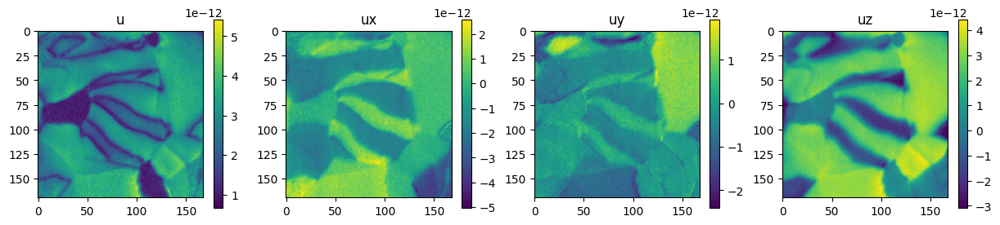

In [15]:
plt.figure(figsize = (15,3))
title = ['u', 'ux', 'uy', 'uz']
for i in range(4):
    plt.subplot(1,4,i+1)
    plt.title(title[i])
    plt.imshow(umaps[title[i]])
    plt.colorbar()

u = umaps['u']; ux=umaps['ux']; uy=umaps['uy']; uz=umaps['uz']

In [16]:
uxyz = np.stack((ux, uy, uz), axis=0)
uxyz.shape

(3, 170, 168)

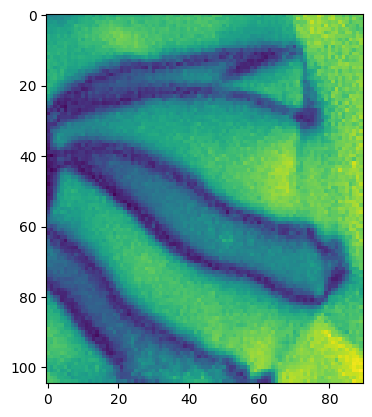

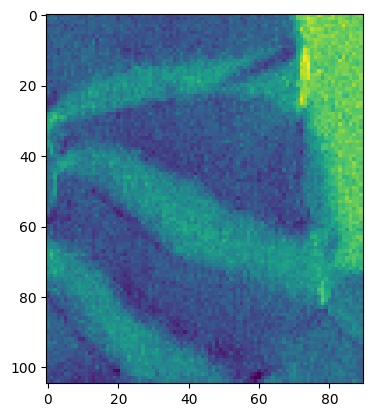

In [17]:
x_cut1 = 30; x_cut2 =135; y_cut1=50; y_cut2=140
expdata = uxyz[:, x_cut1:x_cut2, y_cut1:y_cut2]
struc_img = umaps['u'][x_cut1:x_cut2, y_cut1:y_cut2]

plt.imshow(struc_img)
plt.show()
plt.imshow(expdata[1])

In [9]:
u  = umaps['u'][x_cut1:x_cut2, y_cut1:y_cut2]
ux = umaps['ux'][x_cut1:x_cut2, y_cut1:y_cut2]
uy = umaps['uy'][x_cut1:x_cut2, y_cut1:y_cut2]
uz = umaps['uz'][x_cut1:x_cut2, y_cut1:y_cut2]

# Angle relative to uz (z-axis), in radians
angle = np.arctan2(ux, uy)

struc_img_2 = np.stack([u, angle], axis=-1)

In [10]:
# Extract image patches and spectra
img = norm_(struc_img)

img_2 = struc_img_2.copy()

# Normalize channel 0 independently
c0 = img_2[:, :, 0]
img_2[:, :, 0] = (c0 - c0.min()) / np.ptp(c0)

# Normalize channels 1–3 together
c123 = img_2[:, :, 1:4]
img_2[:, :, 1:4] = (c123 - c123.min()) / np.ptp(c123)

pola3d = expdata

coordinates = get_grid_coords(img, step=1)
coordinates_2 = get_grid_coords(img_2, step=1)
window_size = 8
features_all, coords, _ = get_subimages(img_2, coordinates_2, window_size)
#features_all, coords, _ = get_subimages(img, coordinates, window_size)
features_all = features_all[:,:,:,:]
coords = np.array(coords, dtype=int)
targets = pola3d[:, coords[:, 0], coords[:, 1]]

print('Coordinates shape:', coords.shape)
print('Image patches shape:', features_all.shape)
print('3D map shape:', pola3d.shape)
print('Target 3D map shape:', targets.shape)

Coordinates shape: (8134, 2)
Image patches shape: (8134, 8, 8, 2)
3D map shape: (3, 105, 90)
Target 3D map shape: (3, 8134)


In [11]:
features_3dx, coords, _ = get_subimages(pola3d[0], coordinates, window_size)
features_3dy, coords, _ = get_subimages(pola3d[1], coordinates, window_size)
features_3dz, coords, _ = get_subimages(pola3d[2], coordinates, window_size)
features_3dx = features_3dx[:,:,:,0]
features_3dy = features_3dy[:,:,:,0]
features_3dz = features_3dz[:,:,:,0]

In [12]:
np.savez("expdata.npz", img = norm_(struc_img), pola3d=pola3d)

In [ ]:
# Visualize example patch
k_example = 70
f, (ax1, ax2) = plt.subplots(1, 2, figsize=(7, 3), dpi=100)
ax1.imshow(img, origin='lower')
ax1.scatter(coords[k_example, 1], coords[k_example, 0], marker='x', s=50, c='k')
ax1.axis("off")
ax1.set_title('Full Image')

ax2.imshow(features_all[k_example], origin='lower')
ax2.axis("off")
ax2.set_title('Image Patch')
plt.tight_layout()
plt.show()

plot_3d_vector(features_3dz[k_example], features_3dy[k_example], features_3dz[k_example])

In [14]:
# Prepare data arrays
n, d1, d2, d3 = features_all.shape
X = features_all.reshape(n, d1*d2*d3)  # Flattened patches for DKL

print(f"X_train shape: {X.shape}")
print(f"Coords shape: {coords.shape}")

X_train shape: (8134, 128)
Coords shape: (8134, 2)


In [17]:
# Select initial training points
np.random.seed(90925)
start_size = 3
train_indices = np.random.choice(np.arange(1, n), size=start_size, replace=False)
print("Initial training indices (pool indices):", train_indices)

X_train = X[train_indices]
coord_train = coords[train_indices]

print(f"X_train shape: {X_train.shape}")
print(f"Coordinates shape: {coord_train.shape}")

# Run initial comparison session
start_pair_size = 10 # Number of initial comparison pairs
np.random.seed(1)

# Generate random pairs for initial comparison
random.seed(5)
explicit_start_pairs = list(itertools.combinations(range(len(train_indices)), 2))
selected_pairs = random.sample(explicit_start_pairs, min(start_pair_size, len(explicit_start_pairs)))

Initial training indices (pool indices): [4517 2755  238]
X_train shape: (3, 128)
Coordinates shape: (3, 2)


In [20]:
preference_log = []
confidence_log = []

for idx, (i, j) in enumerate(selected_pairs):
    pool_idx_i = train_indices[i]
    pool_idx_j = train_indices[j]
    
    train_idx1, train_idx2, comp_type, conf = get_user_preference_gui(
        img_full=img,
        coords=coords,
        pool_idx=[pool_idx_i, pool_idx_j],
        features_3dx=features_3dx,
        features_3dy=features_3dy,
        features_3dz=features_3dz,
        train_idx1=i,
        train_idx2=j,
        pair_num=1,
        total_pairs=1,
        confidence_factors=CONFIDENCE_FACTORS,
        allow_ties=ALLOW_TIES,
    )

    preference_log.append([train_idx1, train_idx2, comp_type])
    confidence_log.append(conf)

    # Print what was recorded
    if comp_type == 0:
        print(f"✓ Recorded: train_idx {train_idx1} > train_idx {train_idx2}, confidence={conf:.2f}")
    elif comp_type == 1:
        print(f"✓ Recorded: train_idx {train_idx2} > train_idx {train_idx1}, confidence={conf:.2f}")
    elif comp_type == 2:
        print(f"✓ Recorded: train_idx {train_idx1} ≈ train_idx {train_idx2} (equal), confidence={conf:.2f}")
    print()

# Convert to tensor
train_comp = torch.tensor(preference_log, dtype=torch.long)
confidence = torch.tensor(confidence_log, dtype=torch.float64)
print(f"Initial comparisons shape: {train_comp.shape}")
print(f"Total initial comparisons: {len(train_comp)}")

if ALLOW_TIES:
    n_strict = ((train_comp[:, 2] == 0) | (train_comp[:, 2] == 1)).sum().item()
    n_ties = (train_comp[:, 2] == 2).sum().item()
    print(f"  Strict preferences: {n_strict} ({n_strict/len(train_comp)*100:.1f}%)")
    print(f"  Ties/Equal: {n_ties} ({n_ties/len(train_comp)*100:.1f}%)")

Recorded: 2 > 1 (confidence=1.00)
✓ Recorded: train_idx 2 > train_idx 1, confidence=1.00

Recorded: 0 ≈ 2 (equal, confidence=0.75)
✓ Recorded: train_idx 0 ≈ train_idx 2 (equal), confidence=0.75

Recorded: 0 > 1 (confidence=1.00)
✓ Recorded: train_idx 0 > train_idx 1, confidence=1.00

Initial comparisons shape: torch.Size([3, 3])
Total initial comparisons: 3
  Strict preferences: 2 (66.7%)
  Ties/Equal: 1 (33.3%)


  Initial ties: 1 (33.3%)

Exploration Step 1/20

 Training model...
Training Deep Kernel PairwiseGP Model
Confidence weights:
  min: 0.750, max: 1.000, mean: 0.917
Auto-selected: ConfidenceWeightedMLLWithTies (tie support)

Training Deep Kernel PairwiseGP
  Device: cpu
  Input dim: 128 → Feature dim: 8
  Total comparisons: 3
    Strict: 2, Ties: 1
  MLL: ConfidenceWeightedMLLWithTies
  Epoch 100/1000, Loss: 2.5059
  Epoch 200/1000, Loss: 2.4988
  Epoch 300/1000, Loss: 2.4987
  Epoch 400/1000, Loss: 2.4986
  Epoch 500/1000, Loss: 2.4986
  Epoch 600/1000, Loss: 2.4986
  Epoch 700/1000, Loss: 2.4986
  Epoch 800/1000, Loss: 2.4986
  Epoch 900/1000, Loss: 2.4986
  Epoch 1000/1000, Loss: 2.4986

Training complete! Final loss: 2.4986


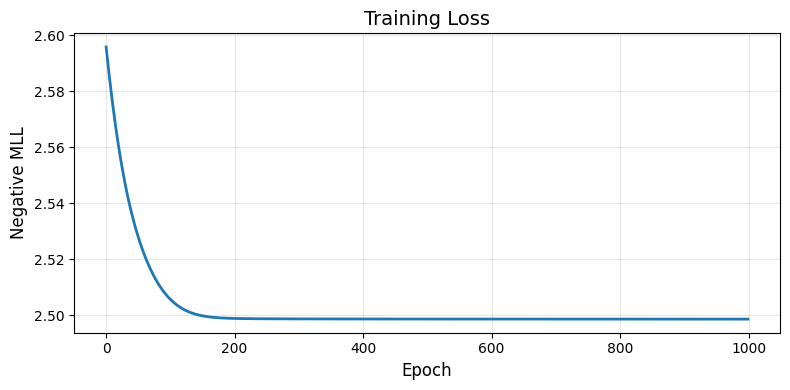

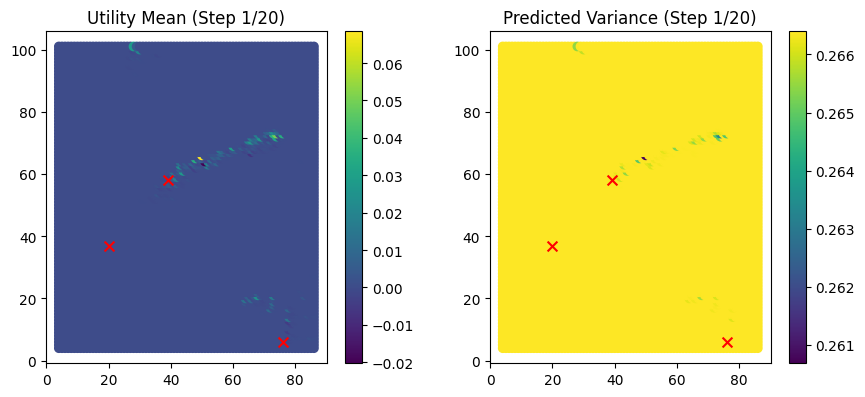


 Acquisition: Selecting next comparison...

UCB Acquisition (beta=10000, strategy='max_vs_uncertain')
  Mean utility: 0.0001 ± 0.0017
  Mean uncertainty: 0.5161 ± 0.0001
  UCB range: [5105.7753, 5161.3683]
  Evaluated 100 pairs
  Skipped 0 duplicate points
  Skipped 0 previously compared pairs
Selected pair: (5631, 8084)
  Selected pool indices: (5631, 8084)
    Point 1: pool_idx=5631, coords=[71 74]
    Point 2: pool_idx=8084, coords=[101  37]

Updating training set...
  Added 2 new points to training set
  New pool indices: [5631, 8084]

Creating comparison pairs...
  Generated 3 comparison pairs

Comparison 1/3
Recorded: 3 ≈ 4 (equal, confidence=0.75)
Recorded: train_idx 3 > train_idx 4
Comparison 2/3
Recorded: 3 > 1 (confidence=1.00)
Recorded: train_idx 1 > train_idx 3
Comparison 3/3
Recorded: 4 > 1 (confidence=1.00)
Recorded: train_idx 1 > train_idx 4

Step 1 Summary
Training set:
  Total points: 5
  Total comparisons: 6
    Strict preferences: 4 (66.7%)
    Ties/Equal: 2 (33.3%)

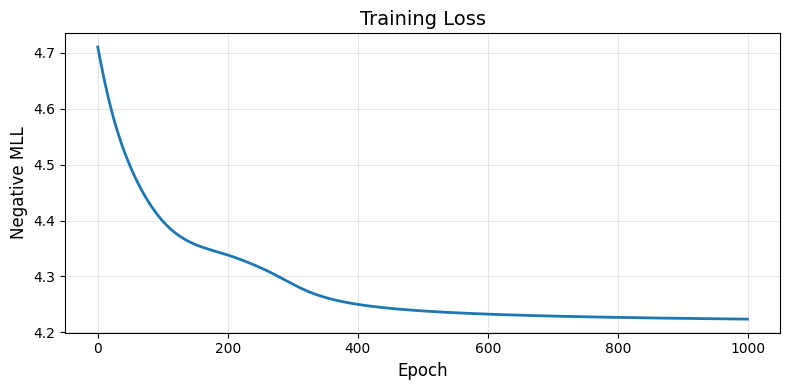

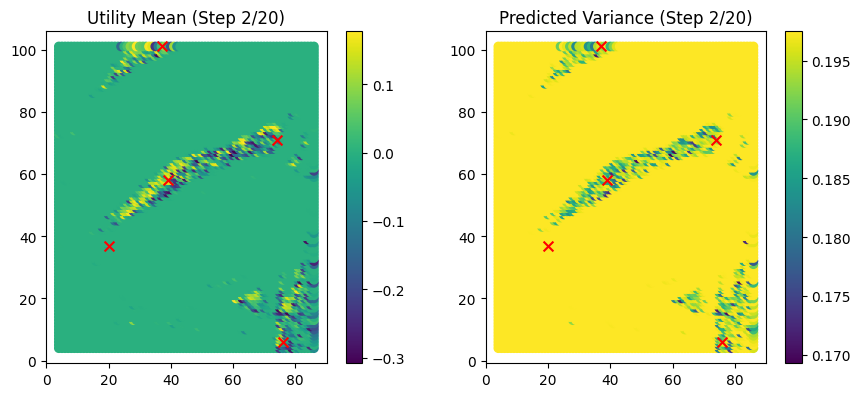


 Acquisition: Selecting next comparison...

UCB Acquisition (beta=10000, strategy='max_vs_uncertain')
  Mean utility: -0.0024 ± 0.0382
  Mean uncertainty: 0.4438 ± 0.0029
  UCB range: [4113.9822, 4443.9564]
  Evaluated 100 pairs
  Skipped 0 duplicate points
  Skipped 0 previously compared pairs
Selected pair: (1169, 6068)
  Selected pool indices: (1169, 6068)
    Point 1: pool_idx=1169, coords=[18 11]
    Point 2: pool_idx=6068, coords=[77 13]

Updating training set...
  Added 2 new points to training set
  New pool indices: [1169, 6068]

Creating comparison pairs...
  Generated 3 comparison pairs

Comparison 1/3
Recorded: 5 > 6 (confidence=1.00)
Recorded: train_idx 5 > train_idx 6
Comparison 2/3
Recorded: 5 > 1 (confidence=1.00)
Recorded: train_idx 1 > train_idx 5
Comparison 3/3
Recorded: 4 > 6 (confidence=1.00)
Recorded: train_idx 4 > train_idx 6

Step 2 Summary
Training set:
  Total points: 7
  Total comparisons: 9
    Strict preferences: 7 (77.8%)
    Ties/Equal: 2 (22.2%)

Confid

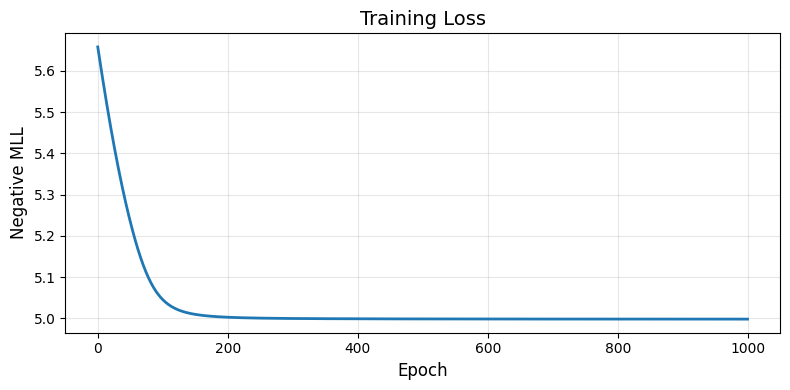

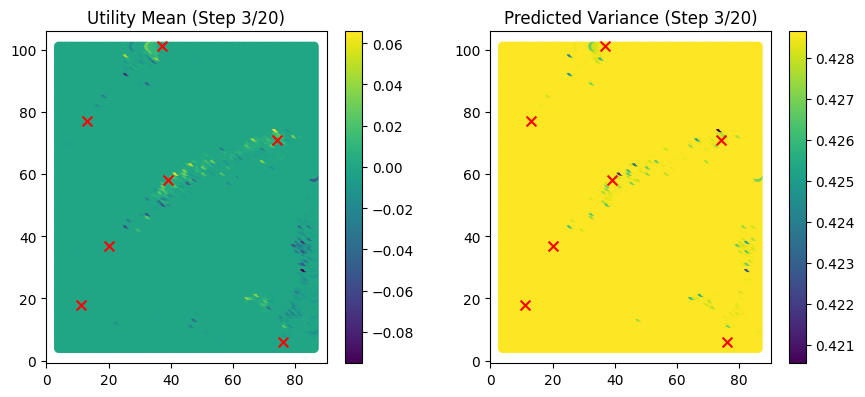


 Acquisition: Selecting next comparison...

UCB Acquisition (beta=10000, strategy='max_vs_uncertain')
  Mean utility: -0.0001 ± 0.0039
  Mean uncertainty: 0.6547 ± 0.0002
  UCB range: [6485.0685, 6547.0880]
  Evaluated 100 pairs
  Skipped 0 duplicate points
  Skipped 0 previously compared pairs
Selected pair: (5037, 6070)
  Selected pool indices: (5037, 6070)
    Point 1: pool_idx=5037, coords=[64 61]
    Point 2: pool_idx=6070, coords=[77 15]

Updating training set...
  Added 2 new points to training set
  New pool indices: [5037, 6070]

Creating comparison pairs...
  Generated 3 comparison pairs

Comparison 1/3
Recorded: 7 > 8 (confidence=1.00)
Recorded: train_idx 7 > train_idx 8
Comparison 2/3
Recorded: 7 > 6 (confidence=1.00)
Recorded: train_idx 6 > train_idx 7
Comparison 3/3
Recorded: 6 ≈ 8 (equal, confidence=0.75)
Recorded: train_idx 6 > train_idx 8

Step 3 Summary
Training set:
  Total points: 9
  Total comparisons: 12
    Strict preferences: 9 (75.0%)
    Ties/Equal: 3 (25.0%)

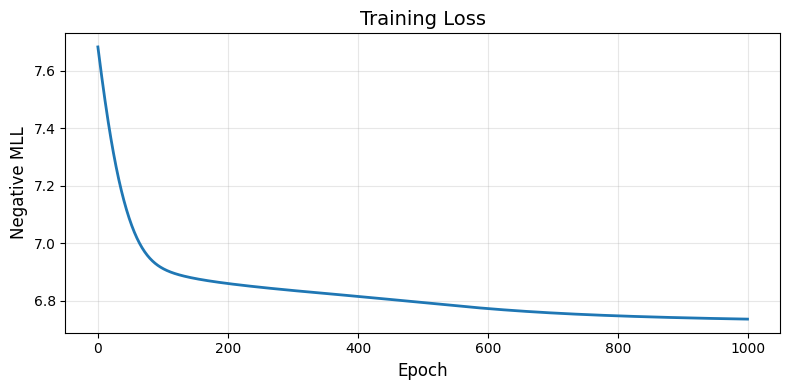

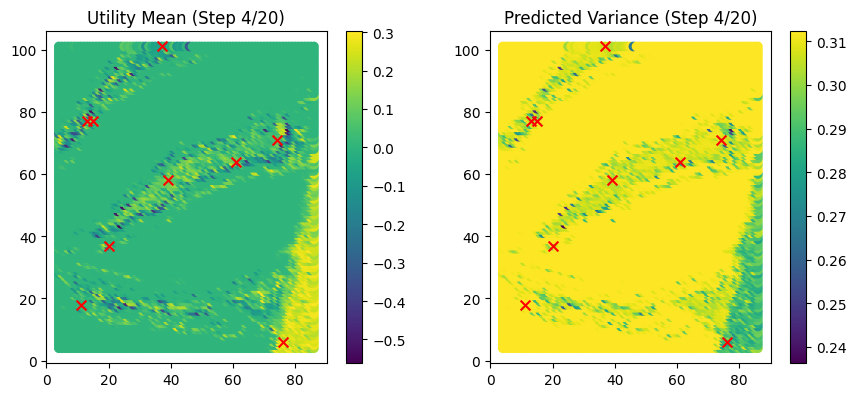


 Acquisition: Selecting next comparison...

UCB Acquisition (beta=10000, strategy='max_vs_uncertain')
  Mean utility: 0.0141 ± 0.0760
  Mean uncertainty: 0.5564 ± 0.0060
  UCB range: [4859.8887, 5587.8937]
  Evaluated 100 pairs
  Skipped 0 duplicate points
  Skipped 0 previously compared pairs
Selected pair: (6225, 8128)
  Selected pool indices: (6225, 8128)
    Point 1: pool_idx=6225, coords=[79  4]
    Point 2: pool_idx=8128, coords=[101  81]

Updating training set...
  Added 2 new points to training set
  New pool indices: [6225, 8128]

Creating comparison pairs...
  Generated 3 comparison pairs

Comparison 1/3
Recorded: 9 > 10 (confidence=1.00)
Recorded: train_idx 9 > train_idx 10
Comparison 2/3
Recorded: 9 > 3 (confidence=1.00)
Recorded: train_idx 3 > train_idx 9
Comparison 3/3
Recorded: 10 > 8 (confidence=1.00)
Recorded: train_idx 8 > train_idx 10

Step 4 Summary
Training set:
  Total points: 11
  Total comparisons: 15
    Strict preferences: 12 (80.0%)
    Ties/Equal: 3 (20.0%)

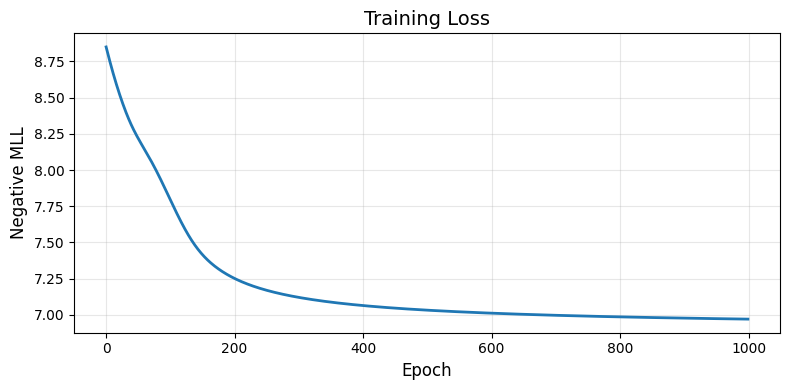

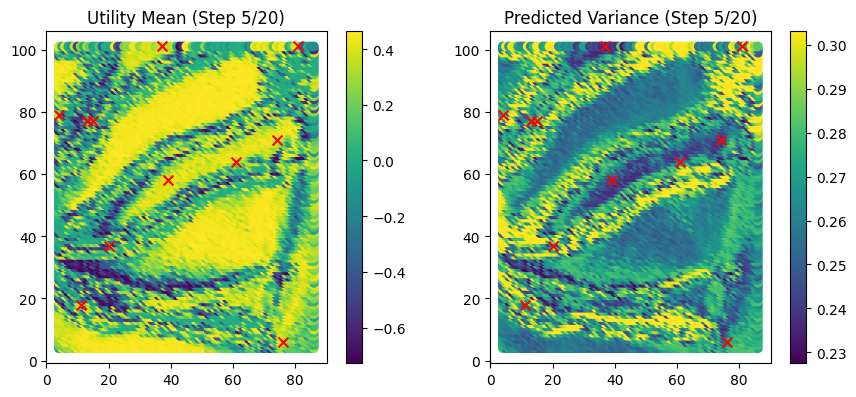


 Acquisition: Selecting next comparison...

UCB Acquisition (beta=10000, strategy='max_vs_uncertain')
  Mean utility: 0.1335 ± 0.3175
  Mean uncertainty: 0.5194 ± 0.0177
  UCB range: [4768.9534, 5505.1982]
  Evaluated 100 pairs
  Skipped 0 duplicate points
  Skipped 0 previously compared pairs
Selected pair: (8105, 7463)
  Selected pool indices: (8105, 7463)
    Point 1: pool_idx=8105, coords=[101  58]
    Point 2: pool_idx=7463, coords=[93 80]

Updating training set...
  Added 2 new points to training set
  New pool indices: [8105, 7463]

Creating comparison pairs...
  Generated 3 comparison pairs

Comparison 1/3
Recorded: 11 ≈ 12 (equal, confidence=0.75)
Recorded: train_idx 11 > train_idx 12
Comparison 2/3
Recorded: 3 ≈ 11 (equal, confidence=0.75)
Recorded: train_idx 3 > train_idx 11
Comparison 3/3
Recorded: 4 ≈ 12 (equal, confidence=0.75)
Recorded: train_idx 4 > train_idx 12

Step 5 Summary
Training set:
  Total points: 13
  Total comparisons: 18
    Strict preferences: 12 (66.7%)


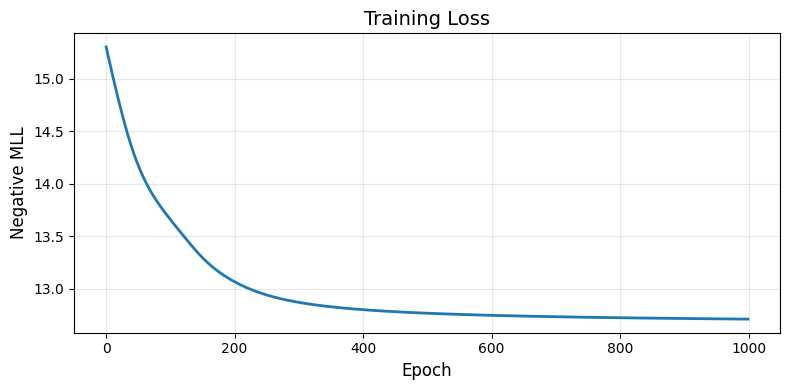

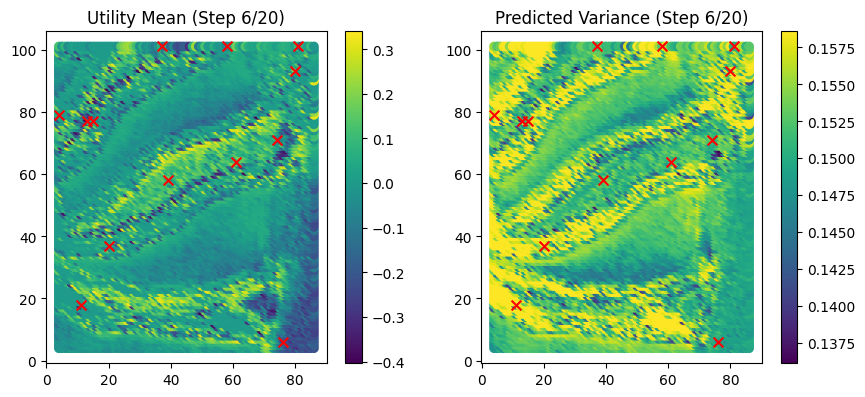


 Acquisition: Selecting next comparison...

UCB Acquisition (beta=10000, strategy='max_vs_uncertain')
  Mean utility: 0.0098 ± 0.1123
  Mean uncertainty: 0.3906 ± 0.0051
  UCB range: [3688.8638, 3982.1462]
  Evaluated 100 pairs
  Skipped 0 duplicate points
  Skipped 0 previously compared pairs
Selected pair: (1519, 6221)
  Selected pool indices: (1519, 6221)
    Point 1: pool_idx=1519, coords=[22 29]
    Point 2: pool_idx=6221, coords=[78 83]

Updating training set...
  Added 2 new points to training set
  New pool indices: [1519, 6221]

Creating comparison pairs...
  Generated 3 comparison pairs

Comparison 1/3
Recorded: 13 ≈ 14 (equal, confidence=0.75)
Recorded: train_idx 13 > train_idx 14
Comparison 2/3
Recorded: 9 > 13 (confidence=1.00)
Recorded: train_idx 9 > train_idx 13
Comparison 3/3
Recorded: 14 > 4 (confidence=1.00)
Recorded: train_idx 4 > train_idx 14

Step 6 Summary
Training set:
  Total points: 15
  Total comparisons: 21
    Strict preferences: 14 (66.7%)
    Ties/Equal: 

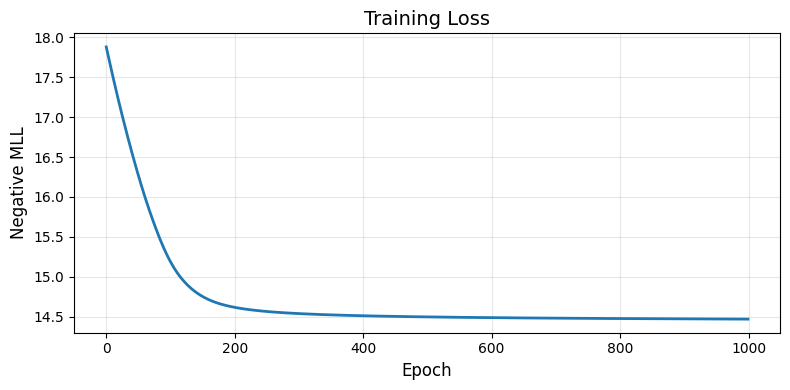

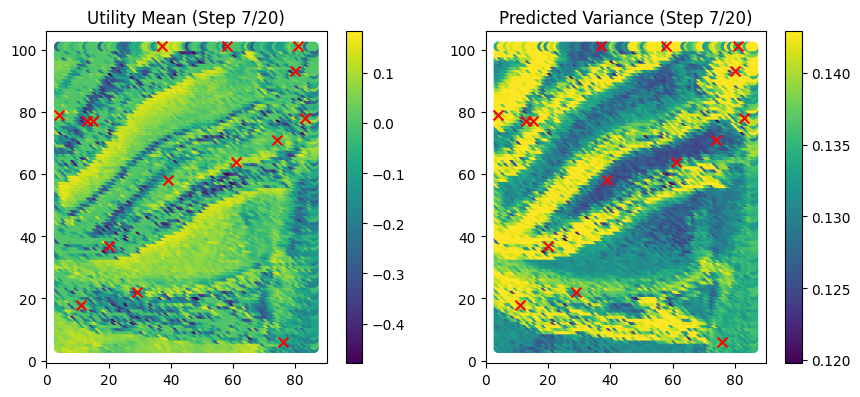


 Acquisition: Selecting next comparison...

UCB Acquisition (beta=10000, strategy='max_vs_uncertain')
  Mean utility: -0.0327 ± 0.1203
  Mean uncertainty: 0.3672 ± 0.0075
  UCB range: [3460.2397, 3780.1258]
  Evaluated 100 pairs
  Skipped 0 duplicate points
  Skipped 0 previously compared pairs
Selected pair: (7894, 7376)
  Selected pool indices: (7894, 7376)
    Point 1: pool_idx=7894, coords=[99 13]
    Point 2: pool_idx=7376, coords=[92 76]

Updating training set...
  Added 2 new points to training set
  New pool indices: [7894, 7376]

Creating comparison pairs...
  Generated 3 comparison pairs

Comparison 1/3
Recorded: 15 ≈ 16 (equal, confidence=0.75)
Recorded: train_idx 15 > train_idx 16
Comparison 2/3
Recorded: 15 > 12 (confidence=0.50)
Recorded: train_idx 12 > train_idx 15
Comparison 3/3
Recorded: 9 > 16 (confidence=1.00)
Recorded: train_idx 9 > train_idx 16

Step 7 Summary
Training set:
  Total points: 17
  Total comparisons: 24
    Strict preferences: 16 (66.7%)
    Ties/Equa

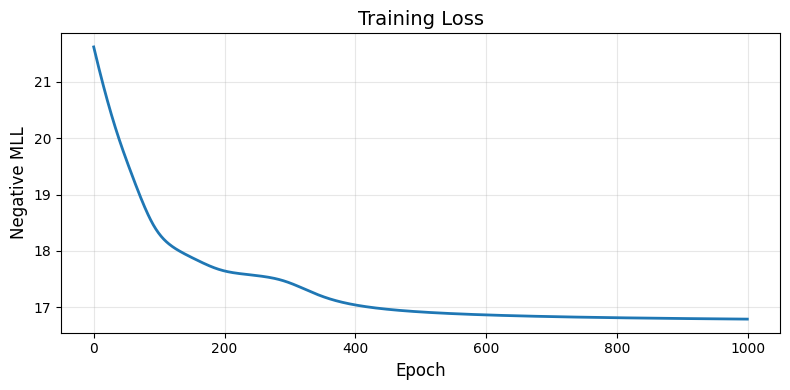

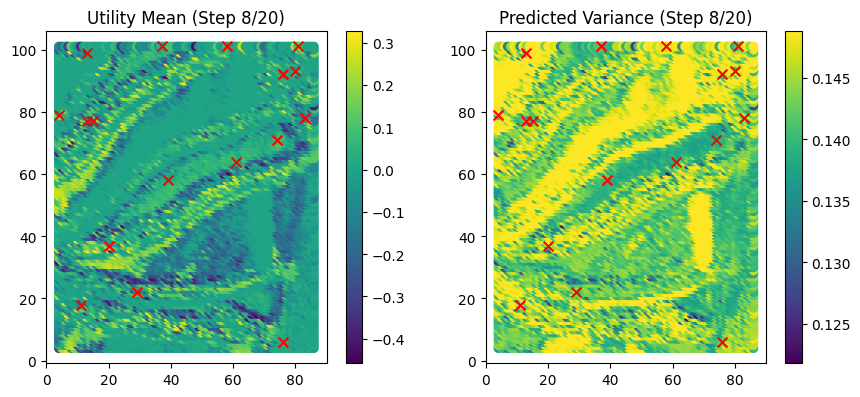


 Acquisition: Selecting next comparison...

UCB Acquisition (beta=10000, strategy='max_vs_uncertain')
  Mean utility: -0.0108 ± 0.1147
  Mean uncertainty: 0.3791 ± 0.0057
  UCB range: [3489.6852, 3857.2065]
  Evaluated 100 pairs
  Skipped 0 duplicate points
  Skipped 0 previously compared pairs
Selected pair: (7255, 7149)
  Selected pool indices: (7255, 7149)
    Point 1: pool_idx=7255, coords=[91 38]
    Point 2: pool_idx=7149, coords=[90 15]

Updating training set...
  Added 2 new points to training set
  New pool indices: [7255, 7149]

Creating comparison pairs...
  Generated 3 comparison pairs

Comparison 1/3
Recorded: 18 > 17 (confidence=1.00)
Recorded: train_idx 17 > train_idx 18
Comparison 2/3
Recorded: 10 > 17 (confidence=1.00)
Recorded: train_idx 10 > train_idx 17
Comparison 3/3
Recorded: 18 > 4 (confidence=1.00)
Recorded: train_idx 4 > train_idx 18

Step 8 Summary
Training set:
  Total points: 19
  Total comparisons: 27
    Strict preferences: 19 (70.4%)
    Ties/Equal: 8 (2

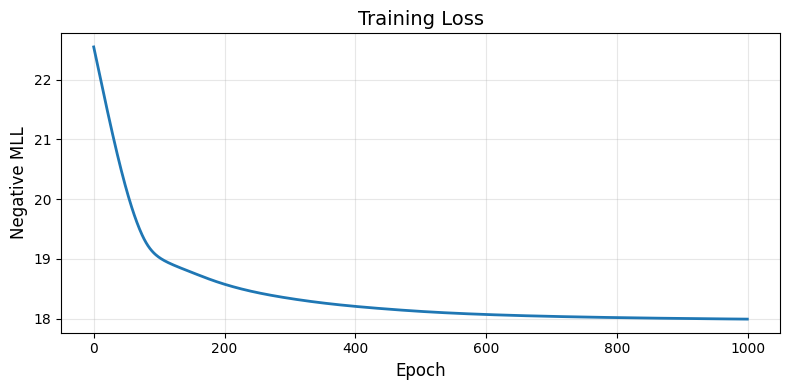

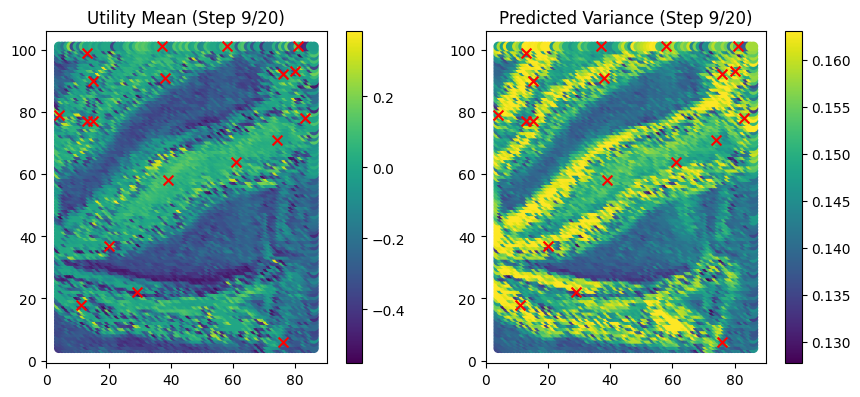


 Acquisition: Selecting next comparison...

UCB Acquisition (beta=10000, strategy='max_vs_uncertain')
  Mean utility: -0.1459 ± 0.1744
  Mean uncertainty: 0.3855 ± 0.0109
  UCB range: [3572.7160, 4037.6491]
  Evaluated 100 pairs
  Skipped 0 duplicate points
  Skipped 0 previously compared pairs
Selected pair: (4759, 5651)
  Selected pool indices: (4759, 5651)
    Point 1: pool_idx=4759, coords=[61 32]
    Point 2: pool_idx=5651, coords=[72 11]

Updating training set...
  Added 2 new points to training set
  New pool indices: [4759, 5651]

Creating comparison pairs...
  Generated 3 comparison pairs

Comparison 1/3
Recorded: 19 > 20 (confidence=1.00)
Recorded: train_idx 19 > train_idx 20
Comparison 2/3
Recorded: 19 > 7 (confidence=1.00)
Recorded: train_idx 7 > train_idx 19
Comparison 3/3
Recorded: 11 > 20 (confidence=1.00)
Recorded: train_idx 11 > train_idx 20

Step 9 Summary
Training set:
  Total points: 21
  Total comparisons: 30
    Strict preferences: 22 (73.3%)
    Ties/Equal: 8 (2

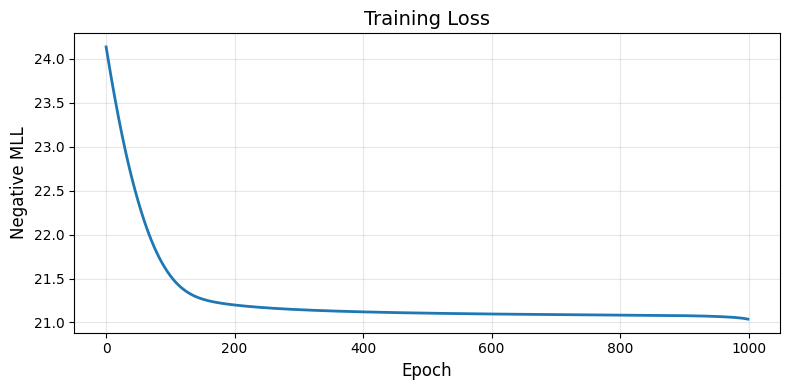

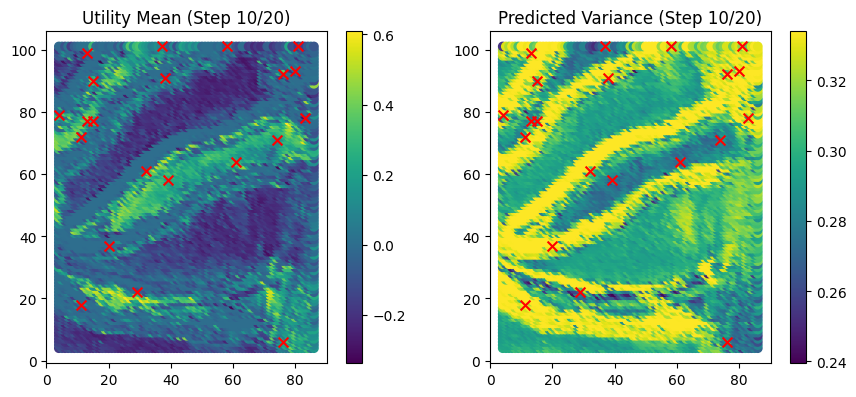


 Acquisition: Selecting next comparison...

UCB Acquisition (beta=10000, strategy='max_vs_uncertain')
  Mean utility: -0.0013 ± 0.1707
  Mean uncertainty: 0.5534 ± 0.0182
  UCB range: [4893.5961, 5779.0284]
  Evaluated 100 pairs
  Skipped 0 duplicate points
  Skipped 0 previously compared pairs
Selected pair: (6794, 7298)
  Selected pool indices: (6794, 7298)
    Point 1: pool_idx=6794, coords=[85 75]
    Point 2: pool_idx=7298, coords=[91 81]

Updating training set...
  Added 2 new points to training set
  New pool indices: [6794, 7298]

Creating comparison pairs...
  Generated 3 comparison pairs

Comparison 1/3
Recorded: 21 > 22 (confidence=1.00)
Recorded: train_idx 21 > train_idx 22
Comparison 2/3
Recorded: 21 > 14 (confidence=1.00)
Recorded: train_idx 14 > train_idx 21
Comparison 3/3
Recorded: 19 > 22 (confidence=1.00)
Recorded: train_idx 19 > train_idx 22

Step 10 Summary
Training set:
  Total points: 23
  Total comparisons: 33
    Strict preferences: 25 (75.8%)
    Ties/Equal: 8

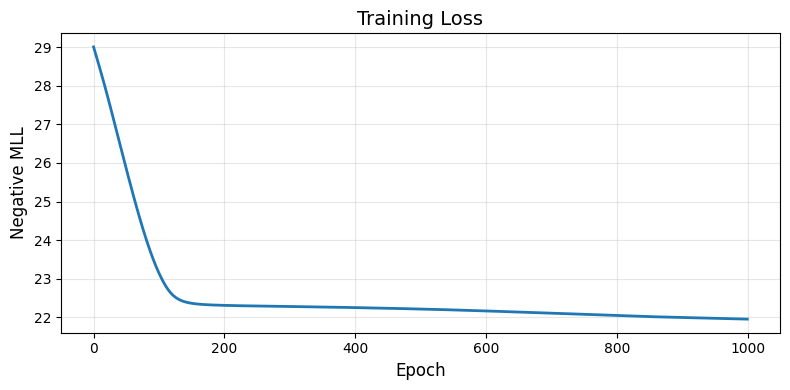

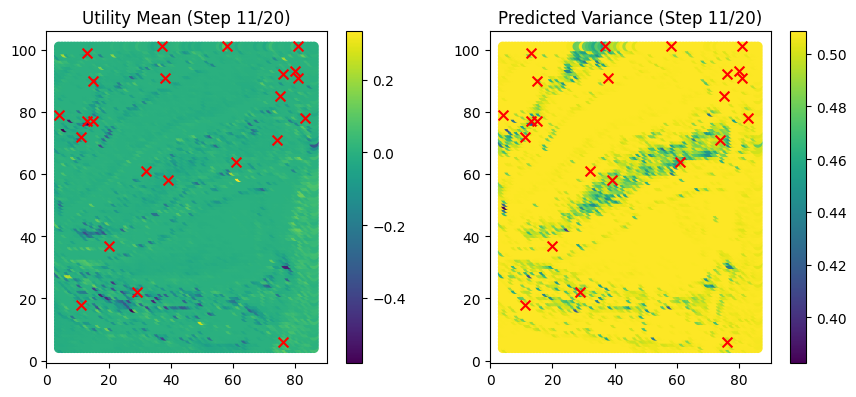


 Acquisition: Selecting next comparison...

UCB Acquisition (beta=2, strategy='max_vs_uncertain')
  Mean utility: -0.0078 ± 0.0452
  Mean uncertainty: 0.7103 ± 0.0073
  UCB range: [0.7038, 1.7098]
  Evaluated 100 pairs
  Skipped 0 duplicate points
  Skipped 0 previously compared pairs
Selected pair: (4623, 7816)
  Selected pool indices: (4623, 7816)
    Point 1: pool_idx=4623, coords=[59 62]
    Point 2: pool_idx=7816, coords=[98 18]

Updating training set...
  Added 2 new points to training set
  New pool indices: [4623, 7816]

Creating comparison pairs...
  Generated 3 comparison pairs

Comparison 1/3
Recorded: 24 > 23 (confidence=1.00)
Recorded: train_idx 23 > train_idx 24
Comparison 2/3
Recorded: 18 > 23 (confidence=1.00)
Recorded: train_idx 18 > train_idx 23
Comparison 3/3
Recorded: 24 > 1 (confidence=1.00)
Recorded: train_idx 1 > train_idx 24

Step 11 Summary
Training set:
  Total points: 25
  Total comparisons: 36
    Strict preferences: 28 (77.8%)
    Ties/Equal: 8 (22.2%)

Co

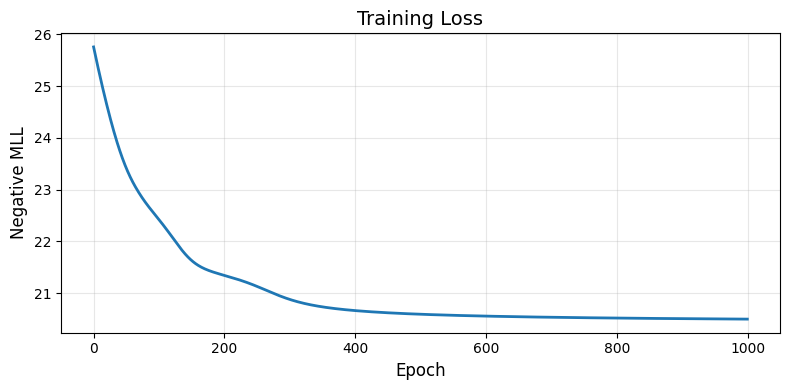

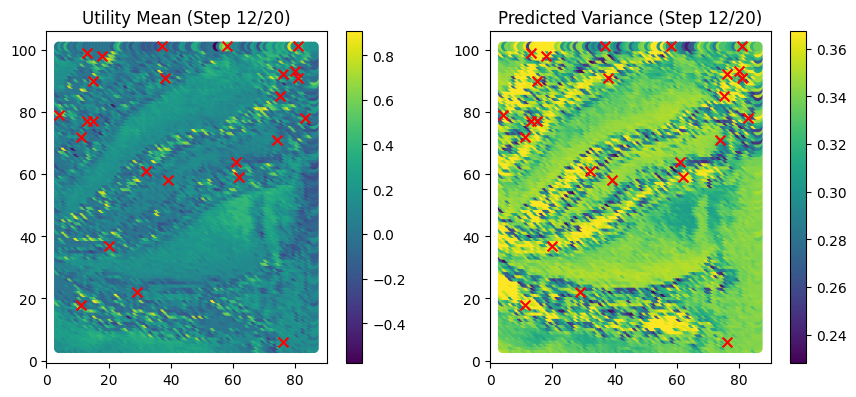


 Acquisition: Selecting next comparison...

UCB Acquisition (beta=2, strategy='max_vs_uncertain')
  Mean utility: 0.1191 ± 0.1618
  Mean uncertainty: 0.5743 ± 0.0234
  UCB range: [0.5173, 1.9433]
  Evaluated 100 pairs
  Skipped 0 duplicate points
  Skipped 0 previously compared pairs
Selected pair: (6541, 6879)
  Selected pool indices: (6541, 6879)
    Point 1: pool_idx=6541, coords=[82 71]
    Point 2: pool_idx=6879, coords=[86 77]

Updating training set...
  Added 2 new points to training set
  New pool indices: [6541, 6879]

Creating comparison pairs...
  Generated 3 comparison pairs

Comparison 1/3
Recorded: 25 > 26 (confidence=1.00)
Recorded: train_idx 25 > train_idx 26
Comparison 2/3
Recorded: 25 > 14 (confidence=1.00)
Recorded: train_idx 14 > train_idx 25
Comparison 3/3
Recorded: 26 > 17 (confidence=1.00)
Recorded: train_idx 17 > train_idx 26

Step 12 Summary
Training set:
  Total points: 27
  Total comparisons: 39
    Strict preferences: 31 (79.5%)
    Ties/Equal: 8 (20.5%)

C

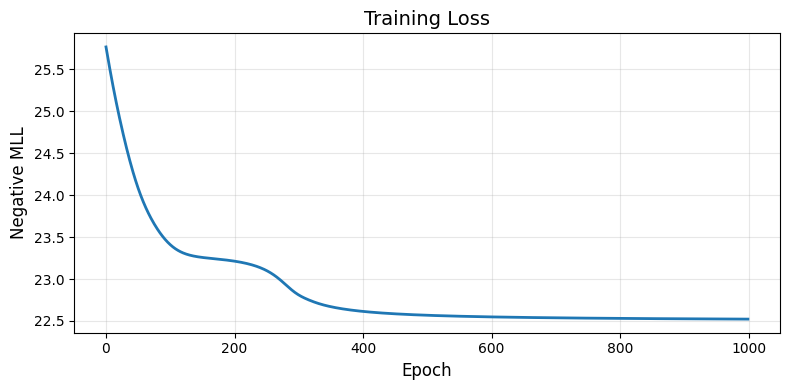

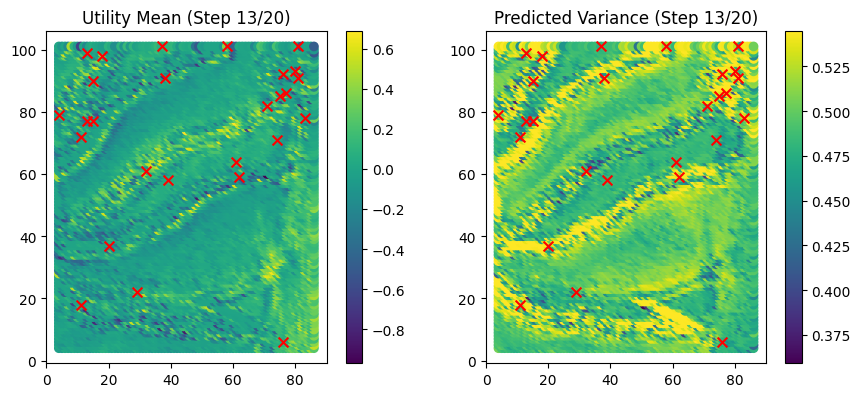


 Acquisition: Selecting next comparison...

UCB Acquisition (beta=2, strategy='max_vs_uncertain')
  Mean utility: 0.0122 ± 0.1704
  Mean uncertainty: 0.7053 ± 0.0192
  UCB range: [0.2914, 2.0295]
  Evaluated 100 pairs
  Skipped 0 duplicate points
  Skipped 0 previously compared pairs
Selected pair: (6116, 7551)
  Selected pool indices: (6116, 7551)
    Point 1: pool_idx=6116, coords=[77 61]
    Point 2: pool_idx=7551, coords=[94 85]

Updating training set...
  Added 2 new points to training set
  New pool indices: [6116, 7551]

Creating comparison pairs...
  Generated 3 comparison pairs

Comparison 1/3
Recorded: 27 > 28 (confidence=1.00)
Recorded: train_idx 27 > train_idx 28
Comparison 2/3
Recorded: 27 > 15 (confidence=1.00)
Recorded: train_idx 15 > train_idx 27
Comparison 3/3
Recorded: 28 > 8 (confidence=1.00)
Recorded: train_idx 8 > train_idx 28

Step 13 Summary
Training set:
  Total points: 29
  Total comparisons: 42
    Strict preferences: 34 (81.0%)
    Ties/Equal: 8 (19.0%)

Con

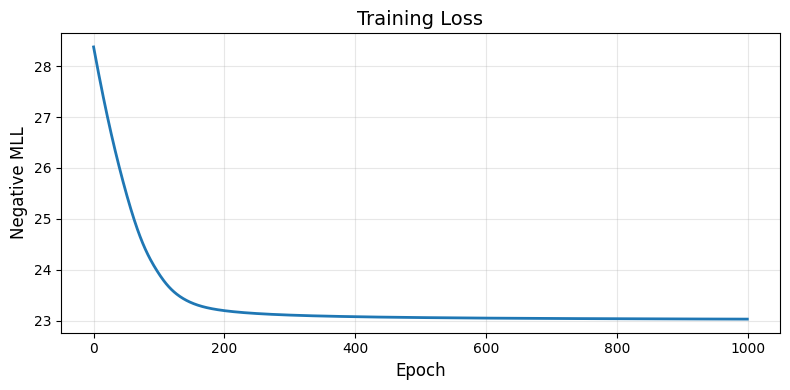

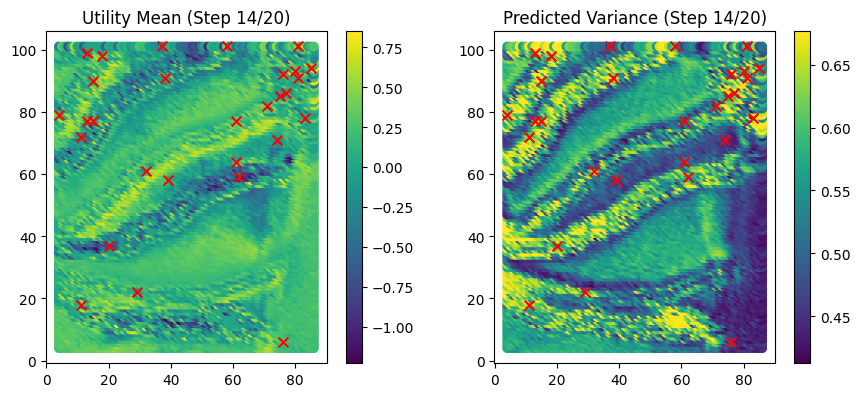


 Acquisition: Selecting next comparison...

UCB Acquisition (beta=2, strategy='max_vs_uncertain')
  Mean utility: 0.1003 ± 0.2897
  Mean uncertainty: 0.7386 ± 0.0450
  UCB range: [0.1546, 2.2590]
  Evaluated 100 pairs
  Skipped 0 duplicate points
  Skipped 0 previously compared pairs
Selected pair: (683, 7214)
  Selected pool indices: (683, 7214)
    Point 1: pool_idx=683, coords=[12 23]
    Point 2: pool_idx=7214, coords=[90 80]

Updating training set...
  Added 2 new points to training set
  New pool indices: [683, 7214]

Creating comparison pairs...
  Generated 3 comparison pairs

Comparison 1/3
Recorded: 30 > 29 (confidence=1.00)
Recorded: train_idx 29 > train_idx 30
Comparison 2/3
Recorded: 29 > 8 (confidence=1.00)
Recorded: train_idx 8 > train_idx 29
Comparison 3/3
Recorded: 9 > 30 (confidence=1.00)
Recorded: train_idx 9 > train_idx 30

Step 14 Summary
Training set:
  Total points: 31
  Total comparisons: 45
    Strict preferences: 37 (82.2%)
    Ties/Equal: 8 (17.8%)

Confidenc

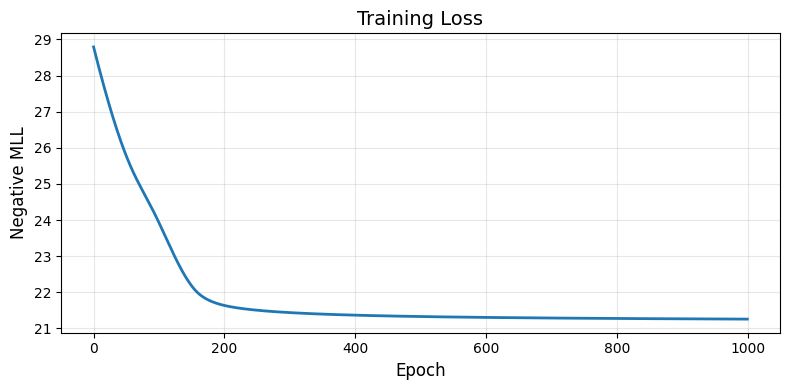

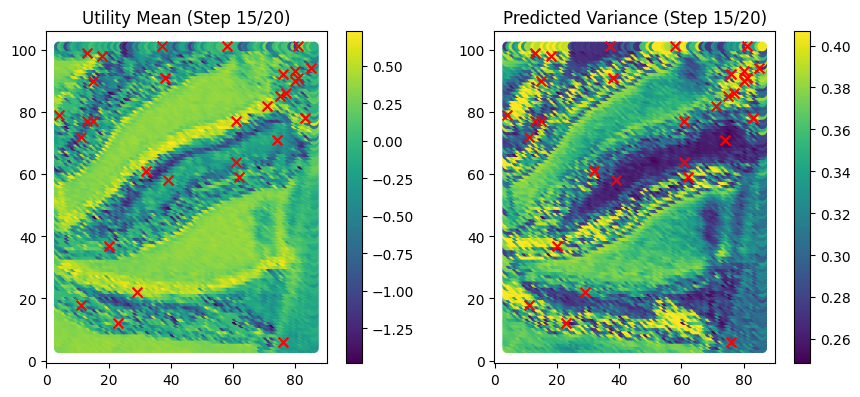


 Acquisition: Selecting next comparison...

UCB Acquisition (beta=2, strategy='max_vs_uncertain')
  Mean utility: -0.0133 ± 0.4229
  Mean uncertainty: 0.5749 ± 0.0370
  UCB range: [-0.4822, 1.8518]
  Evaluated 100 pairs
  Skipped 0 duplicate points
  Skipped 0 previously compared pairs
Selected pair: (5598, 6978)
  Selected pool indices: (5598, 6978)
    Point 1: pool_idx=5598, coords=[71 41]
    Point 2: pool_idx=6978, coords=[88 10]

Updating training set...
  Added 2 new points to training set
  New pool indices: [5598, 6978]

Creating comparison pairs...
  Generated 3 comparison pairs

Comparison 1/3
Recorded: 32 > 31 (confidence=1.00)
Recorded: train_idx 31 > train_idx 32
Comparison 2/3
Recorded: 31 > 3 (confidence=1.00)
Recorded: train_idx 3 > train_idx 31
Comparison 3/3
Recorded: 19 ≈ 32 (equal, confidence=0.75)
Recorded: train_idx 19 > train_idx 32

Step 15 Summary
Training set:
  Total points: 33
  Total comparisons: 48
    Strict preferences: 39 (81.2%)
    Ties/Equal: 9 (18

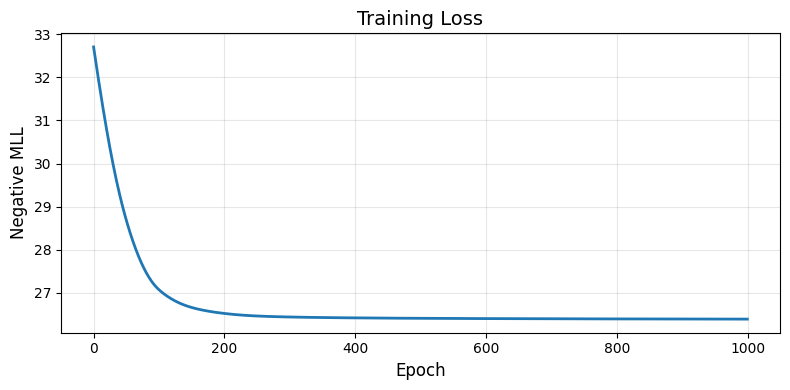

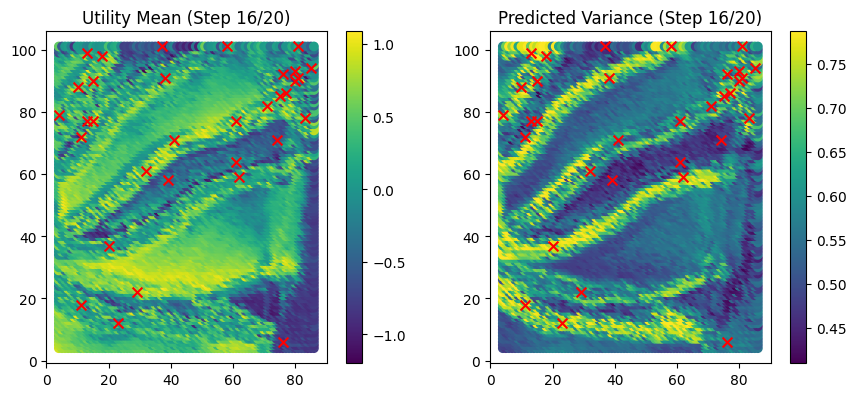


 Acquisition: Selecting next comparison...

UCB Acquisition (beta=2, strategy='max_vs_uncertain')
  Mean utility: 0.1636 ± 0.4716
  Mean uncertainty: 0.7597 ± 0.0573
  UCB range: [0.2516, 2.5149]
  Evaluated 100 pairs
  Skipped 0 duplicate points
  Skipped 0 previously compared pairs
Selected pair: (5094, 6406)
  Selected pool indices: (5094, 6406)
    Point 1: pool_idx=5094, coords=[65 35]
    Point 2: pool_idx=6406, coords=[81 19]

Updating training set...
  Added 2 new points to training set
  New pool indices: [5094, 6406]

Creating comparison pairs...
  Generated 3 comparison pairs

Comparison 1/3
Recorded: 33 > 34 (confidence=1.00)
Recorded: train_idx 33 > train_idx 34
Comparison 2/3
Recorded: 33 > 13 (confidence=1.00)
Recorded: train_idx 13 > train_idx 33
Comparison 3/3
Recorded: 0 > 34 (confidence=1.00)
Recorded: train_idx 0 > train_idx 34

Step 16 Summary
Training set:
  Total points: 35
  Total comparisons: 51
    Strict preferences: 42 (82.4%)
    Ties/Equal: 9 (17.6%)

Con

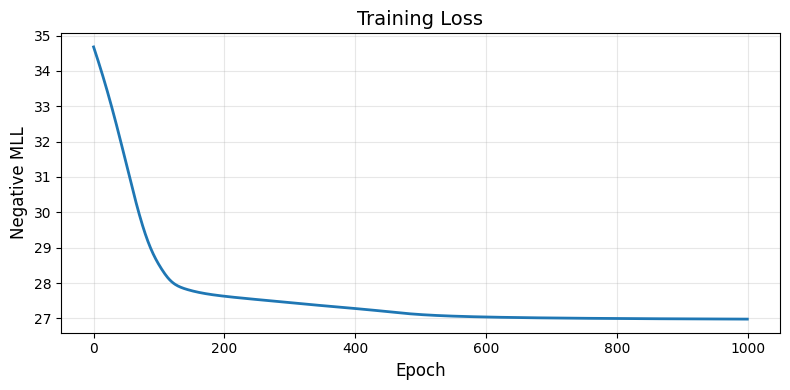

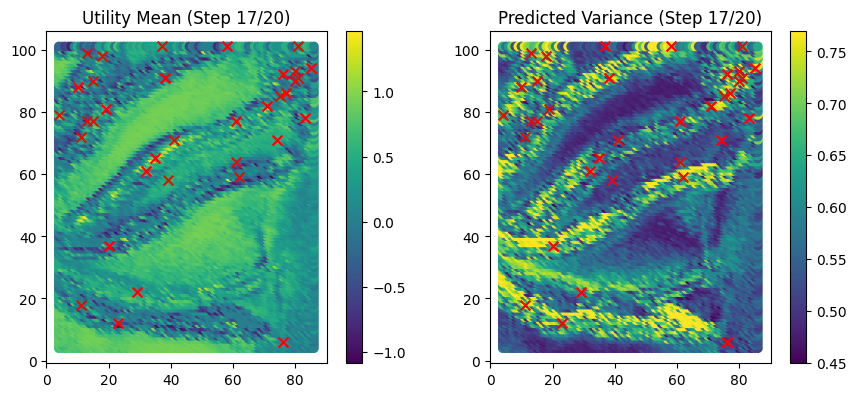


 Acquisition: Selecting next comparison...

UCB Acquisition (beta=2, strategy='max_vs_uncertain')
  Mean utility: 0.3464 ± 0.4101
  Mean uncertainty: 0.7630 ± 0.0509
  UCB range: [0.2869, 2.8571]
  Evaluated 100 pairs
  Skipped 0 duplicate points
  Skipped 0 previously compared pairs
Selected pair: (5093, 7635)
  Selected pool indices: (5093, 7635)
    Point 1: pool_idx=5093, coords=[65 34]
    Point 2: pool_idx=7635, coords=[95 86]

Updating training set...
  Added 2 new points to training set
  New pool indices: [5093, 7635]

Creating comparison pairs...
  Generated 3 comparison pairs

Comparison 1/3
Recorded: 35 > 36 (confidence=1.00)
Recorded: train_idx 35 > train_idx 36
Comparison 2/3
Recorded: 35 > 23 (confidence=1.00)
Recorded: train_idx 23 > train_idx 35
Comparison 3/3
Recorded: 30 ≈ 36 (equal, confidence=1.00)
Recorded: train_idx 30 > train_idx 36

Step 17 Summary
Training set:
  Total points: 37
  Total comparisons: 54
    Strict preferences: 44 (81.5%)
    Ties/Equal: 10 (1

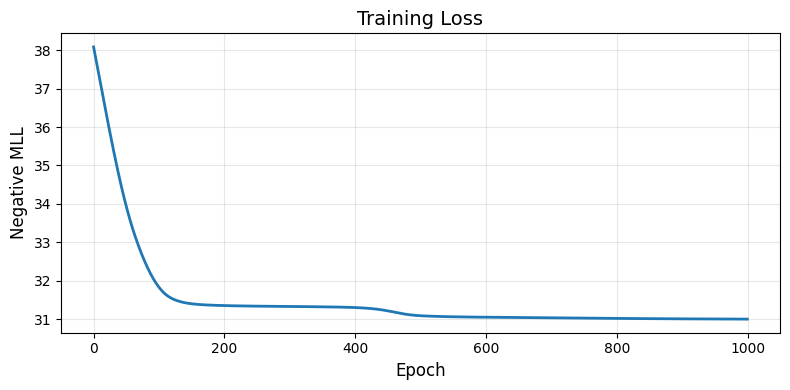

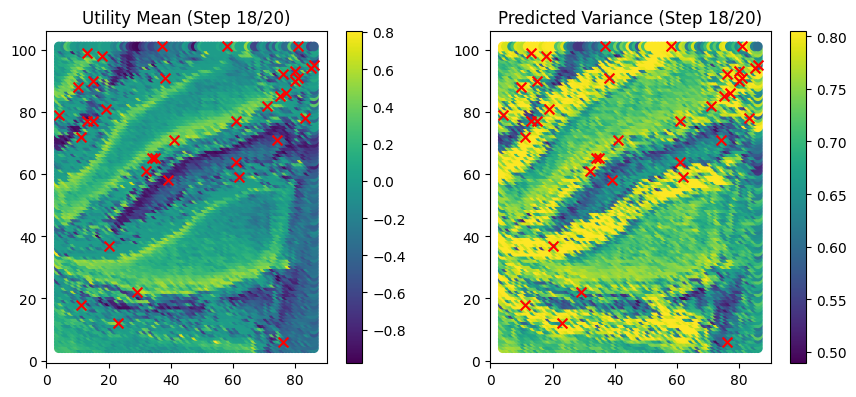


 Acquisition: Selecting next comparison...

UCB Acquisition (beta=2, strategy='max_vs_uncertain')
  Mean utility: -0.0683 ± 0.3283
  Mean uncertainty: 0.8415 ± 0.0418
  UCB range: [0.4912, 2.4272]
  Evaluated 100 pairs
  Skipped 0 duplicate points
  Skipped 0 previously compared pairs
Selected pair: (2573, 6811)
  Selected pool indices: (2573, 6811)
    Point 1: pool_idx=2573, coords=[35  4]
    Point 2: pool_idx=6811, coords=[86  9]

Updating training set...
  Added 2 new points to training set
  New pool indices: [2573, 6811]

Creating comparison pairs...
  Generated 3 comparison pairs

Comparison 1/3
Recorded: 38 > 37 (confidence=1.00)
Recorded: train_idx 37 > train_idx 38
Comparison 2/3
Recorded: 33 > 37 (confidence=1.00)
Recorded: train_idx 33 > train_idx 37
Comparison 3/3
Recorded: 38 > 26 (confidence=1.00)
Recorded: train_idx 26 > train_idx 38

Step 18 Summary
Training set:
  Total points: 39
  Total comparisons: 57
    Strict preferences: 47 (82.5%)
    Ties/Equal: 10 (17.5%)


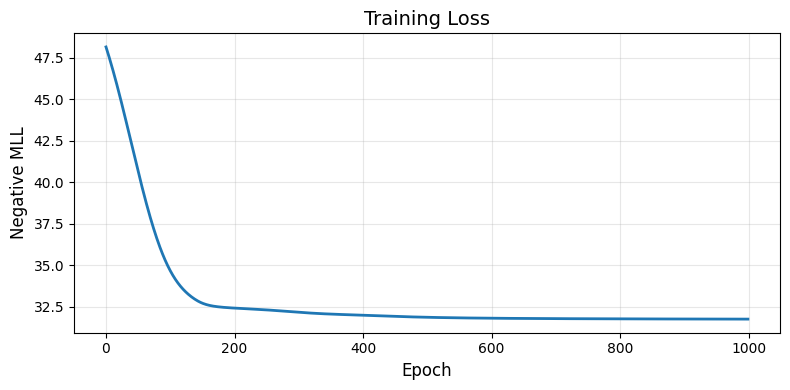

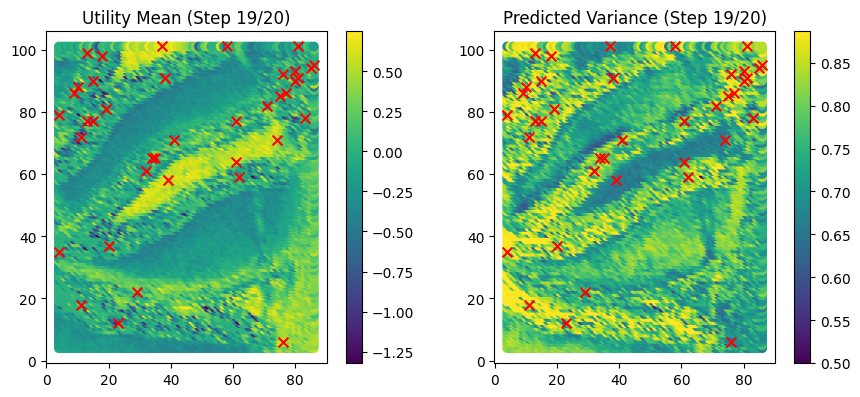


 Acquisition: Selecting next comparison...

UCB Acquisition (beta=2, strategy='max_vs_uncertain')
  Mean utility: -0.0219 ± 0.3125
  Mean uncertainty: 0.8751 ± 0.0393
  UCB range: [0.1331, 2.4247]
  Evaluated 100 pairs
  Skipped 0 duplicate points
  Skipped 0 previously compared pairs
Selected pair: (1476, 6898)
  Selected pool indices: (1476, 6898)
    Point 1: pool_idx=1476, coords=[21 69]
    Point 2: pool_idx=6898, coords=[87 13]

Updating training set...
  Added 2 new points to training set
  New pool indices: [1476, 6898]

Creating comparison pairs...
  Generated 3 comparison pairs

Comparison 1/3
Recorded: 40 > 39 (confidence=1.00)
Recorded: train_idx 39 > train_idx 40
Comparison 2/3
Recorded: 11 ≈ 39 (equal, confidence=0.75)
Recorded: train_idx 11 > train_idx 39
Comparison 3/3
Recorded: 40 > 7 (confidence=1.00)
Recorded: train_idx 7 > train_idx 40

Step 19 Summary
Training set:
  Total points: 41
  Total comparisons: 60
    Strict preferences: 49 (81.7%)
    Ties/Equal: 11 (18

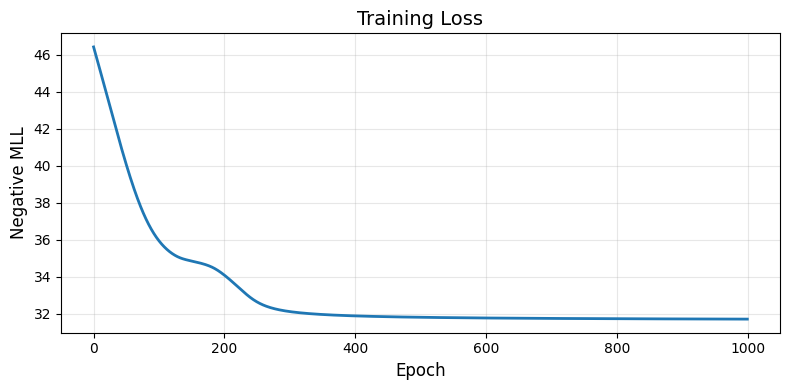

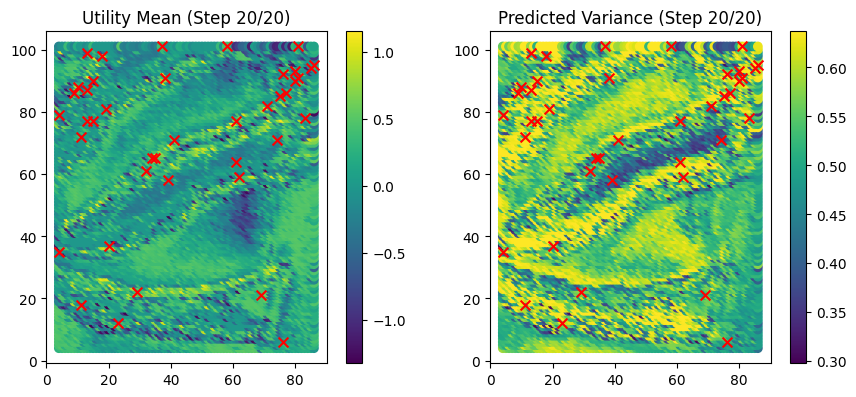


 Acquisition: Selecting next comparison...

UCB Acquisition (beta=2, strategy='max_vs_uncertain')
  Mean utility: 0.0863 ± 0.3641
  Mean uncertainty: 0.7340 ± 0.0506
  UCB range: [-0.2260, 2.4100]
  Evaluated 100 pairs
  Skipped 0 duplicate points
  Skipped 0 previously compared pairs
Selected pair: (6541, 8068)
  Selected pool indices: (6541, 8068)
    Point 1: pool_idx=6541, coords=[82 71]
    Point 2: pool_idx=8068, coords=[101  21]

Updating training set...
  Added 1 new points to training set
  New pool indices: [8068]

Creating comparison pairs...
  Generated 2 comparison pairs

Comparison 1/2
Recorded: 41 > 25 (confidence=1.00)
Recorded: train_idx 25 > train_idx 41
Comparison 2/2
Recorded: 41 > 2 (confidence=1.00)
Recorded: train_idx 2 > train_idx 41

Step 20 Summary
Training set:
  Total points: 42
  Total comparisons: 62
    Strict preferences: 51 (82.3%)
    Ties/Equal: 11 (17.7%)

Confidence statistics:
  Mean: 0.952
  Range: [0.500, 1.000]

Acquisition:
  Unique pairs trac

In [23]:
# ========== PARAMETERS ==========
psize = 89
exploration_steps = 20
num_epochs = 1000
top_k = 100
n_pairs_per_point = 1
seed = 0

# Track previous comparisons (pool indices)
previous_comparisons = set()

# Track comparisons from initial data
# Note: train_comp now has 3 columns if ties are enabled
for comp in train_comp:
    i, j = comp[0].item(), comp[1].item()
    pool_i, pool_j = train_indices[i], train_indices[j]
    previous_comparisons.add((pool_i, pool_j))
    previous_comparisons.add((pool_j, pool_i))  # Add both directions

# Tracking metrics
ssim_all = []
mse_all = []
n_ties_history = []

if ALLOW_TIES:
    n_ties_init = (train_comp[:, 2] == 2).sum().item()
    print(f"  Initial ties: {n_ties_init} ({n_ties_init/len(train_comp)*100:.1f}%)")
print()

# ========== MAIN LOOP ==========
for e in range(exploration_steps):

    if e <10:
        beta = 10000
    else:
        beta = 2

    print(f"Exploration Step {e+1}/{exploration_steps}")

    # ========== TRAIN MODEL ==========
    print(f"\n Training model...")
    mll, pref_model, dkl_model = fit_dkpg(X_train, train_comp, confidence_weights=confidence,
                                        allow_ties=ALLOW_TIES, tolerance=TOLERANCE, feature_dim=8,
                                        num_epochs=num_epochs, verbose=True)
    # ========== PREDICT ON ALL DATA ==========
    mean, var = predict_utility(dkl_model, X)

    # Track tie statistics
    if ALLOW_TIES:
        n_ties = (train_comp[:, 2] == 2).sum().item()
        n_ties_history.append(n_ties)


    # Find current best in training set
    train_means, _ = predict_utility(dkl_model, X_train)
    best_train_idx = np.argmax(train_means)

    # ========== VISUALIZE PREDICTION ==========
    coord_train = coords[train_indices]
    plot_predictions(coords, coord_train, mean, var,
                    step=e+1, total_steps=exploration_steps)

    # ========== ACQUISITION FUNCTION ==========
    print(f"\n Acquisition: Selecting next comparison...")
    selected_points = acq_ucb(dkl_model=dkl_model, X_pool=X,
                            previous_comparisons=previous_comparisons,
                            top_k=top_k, beta=beta, strategy='max_vs_uncertain')


    print(f"  Selected pool indices: {selected_points}")
    print(f"    Point 1: pool_idx={selected_points[0]}, coords={coords[selected_points[0]]}")
    print(f"    Point 2: pool_idx={selected_points[1]}, coords={coords[selected_points[1]]}")

    # Track this comparison
    previous_comparisons.add((selected_points[0], selected_points[1]))
    previous_comparisons.add((selected_points[1], selected_points[0]))

    # ========== UPDATE TRAINING SET ==========
    print(f"\nUpdating training set...")
    new_indices = []
    for idx in selected_points:
        if idx not in train_indices:
            new_indices.append(idx)

    if len(new_indices) > 0:
        train_indices = np.append(train_indices, new_indices)
        X_train = X[train_indices]
        print(f"  Added {len(new_indices)} new points to training set")
        print(f"  New pool indices: {new_indices}")
    else:
        print("  Both points already in training set")

    # ========== CREATE COMPARISON PAIRS ==========
    print(f"\nCreating comparison pairs...")
    comparison_pairs = sample_comparison_pairs(
        train_indices=train_indices,
        n_pairs_per_point=n_pairs_per_point,
        best_train_idx=best_train_idx if len(new_indices) == 1 else None,
        seed=seed + e)
    print(f"  Generated {len(comparison_pairs)} comparison pairs")

    # ========== GET PREFERENCES WITH TIE SUPPORT ==========
    print(f"\n Collecting preferences...")
    new_preference, new_confidence = acquire_preference(
        img_full=struc_img,
        train_indices=train_indices,
        comparison_pairs=comparison_pairs,
        coords=coords,
        confidence_factors=CONFIDENCE_FACTORS,
        allow_ties=ALLOW_TIES,      # Enable tie option
    )

    # ========== UPDATE COMPARISON SET ==========
    # Note: new_preference has shape (n_pairs, 3) if ties are enabled
    train_comp = torch.cat([train_comp, new_preference], dim=0)
    confidence = torch.cat([confidence, new_confidence], dim=0)

    # ========== STEP SUMMARY ==========
    print(f"\n{'='*60}")
    print(f"Step {e+1} Summary")
    print(f"{'='*60}")
    print(f"Training set:")
    print(f"  Total points: {len(X_train)}")
    print(f"  Total comparisons: {len(train_comp)}")

    if ALLOW_TIES:
        n_strict = ((train_comp[:, 2] == 0) | (train_comp[:, 2] == 1)).sum().item()
        n_ties_current = (train_comp[:, 2] == 2).sum().item()
        print(f"    Strict preferences: {n_strict} ({n_strict/len(train_comp)*100:.1f}%)")
        print(f"    Ties/Equal: {n_ties_current} ({n_ties_current/len(train_comp)*100:.1f}%)")

    print(f"\nConfidence statistics:")
    print(f"  Mean: {confidence.mean():.3f}")
    print(f"  Range: [{confidence.min():.3f}, {confidence.max():.3f}]")

    print(f"\nAcquisition:")
    print(f"  Unique pairs tracked: {len(previous_comparisons)//2}")

    # ========== SAVE RESULTS ==========
    save_data = {
        'train_indices': train_indices,
        'mean': mean,
        'var': var,
        'train_comp': train_comp.numpy(),  # Shape: (n, 3) with ties
        'confidence': confidence.numpy(),
        'comparison_pairs': comparison_pairs,
        'train_means': train_means}

    if ALLOW_TIES:
        save_data['n_ties'] = n_ties_current
        save_data['tie_percentage'] = n_ties_current / len(train_comp) * 100

    np.savez(
        f"step_{e}.npz",
        **save_data
    )

    print(f"\n✓ Results saved to step_{e}.npz")

# ========== FINAL SUMMARY ==========
print(f"\n{'='*80}")
print(f"ACTIVE LEARNING COMPLETE")
print(f"\nFinal Statistics:")
print(f"  Total steps: {exploration_steps}")
print(f"  Final training points: {len(train_indices)}")
print(f"  Final comparisons: {len(train_comp)}")

if ALLOW_TIES:
    n_ties_final = (train_comp[:, 2] == 2).sum().item()
    print(f"    Strict: {len(train_comp) - n_ties_final}")
    print(f"    Ties: {n_ties_final} ({n_ties_final/len(train_comp)*100:.1f}%)")

print(f"\nConfidence:")
print(f"  Overall mean: {confidence.mean():.3f}")
print(f"  Overall range: [{confidence.min():.3f}, {confidence.max():.3f}]")

Training Deep Kernel PairwiseGP Model
Auto-selected: ConfidenceWeightedMLLWithTies (tie support)

Training Deep Kernel PairwiseGP
  Device: cpu
  Input dim: 128 → Feature dim: 16
  Total comparisons: 62
    Strict: 51, Ties: 11
  MLL: ConfidenceWeightedMLLWithTies
  Epoch 100/1000, Loss: 40.3907
  Epoch 200/1000, Loss: 39.9507
  Epoch 300/1000, Loss: 39.7828
  Epoch 400/1000, Loss: 39.7140
  Epoch 500/1000, Loss: 39.6766
  Epoch 600/1000, Loss: 39.6527
  Epoch 700/1000, Loss: 39.6360
  Epoch 800/1000, Loss: 39.6236
  Epoch 900/1000, Loss: 39.6140
  Epoch 1000/1000, Loss: 39.6064

Training complete! Final loss: 39.6064


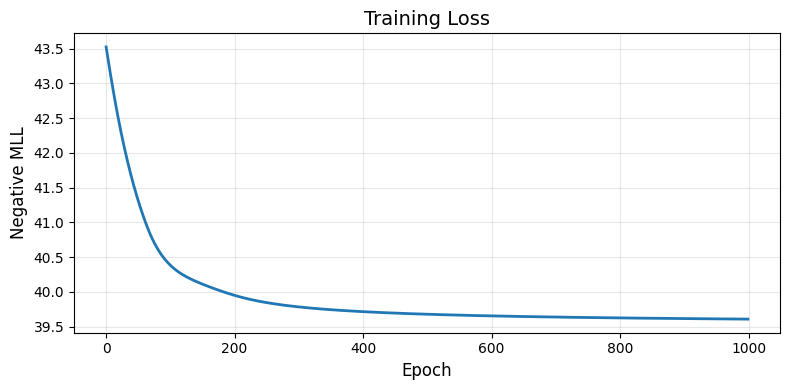

In [24]:
## Final Model
_,  _, dkl_model = fit_dkpg(X_train, train_comp, num_epochs=num_epochs, allow_ties = ALLOW_TIES)

# ===== PREDICT ON ALL DATA =====
mean, var = predict_utility(dkl_model, X)

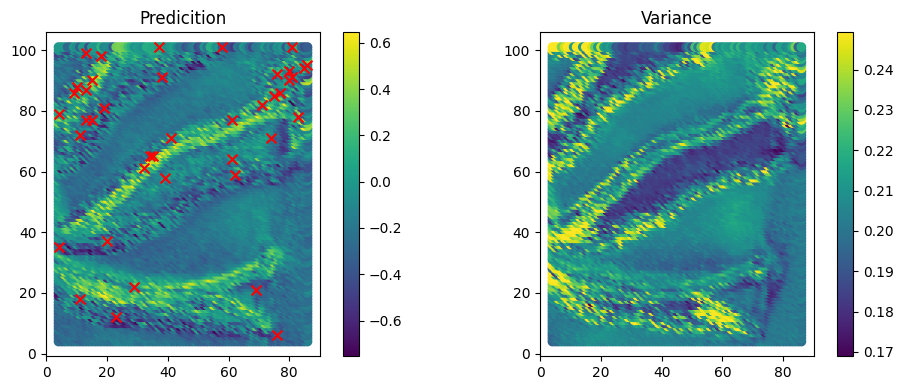

In [26]:
_, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), dpi=100)


a = ax1.scatter(coords[:, 1], coords[:, 0], c=mean, cmap="viridis")
plt.colorbar(a, ax=ax1)
ax1.scatter(coord_train[:, 1], coord_train[:, 0], s=50, c='red', marker='x')
ax1.set_title(f'Predicition')
ax1.set_aspect('equal')

# Predicted utility mean
b = ax2.scatter(coords[:, 1], coords[:, 0], c=var, cmap="viridis")
plt.colorbar(b, ax=ax2)
ax2.set_title(f'Variance')
ax2.set_aspect('equal')

plt.tight_layout()
plt.show()

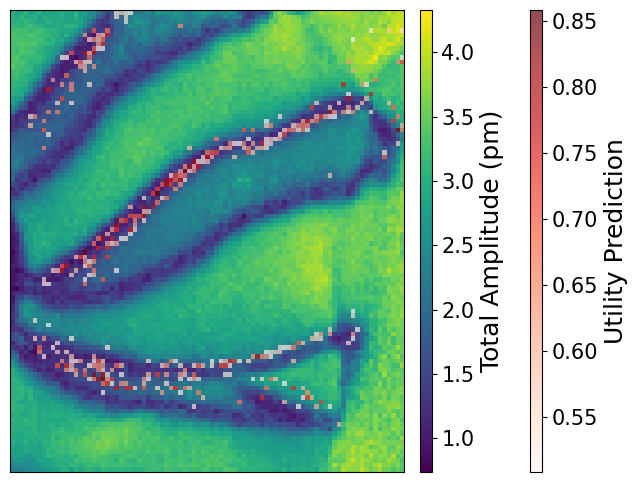

In [36]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# -----------------------------
# Build utility map
# -----------------------------
values = mean.flatten() + (var.flatten())

rows = coords[:, 0]
cols = coords[:, 1]

nrows = rows.max() + 1
ncols = cols.max() + 1

grid = np.full((nrows, ncols), np.nan)
grid[rows, cols] = values

threshold = np.nanpercentile(grid, 95)
masked_grid = np.ma.masked_where(grid < threshold, grid)

# -----------------------------
# Figure
# -----------------------------
fig, ax = plt.subplots(figsize=(8, 6), dpi=100, frameon=False)

# Shift everything slightly left to make room for colorbars
fig.subplots_adjust(right=0.72)

# Base image
im_base = ax.imshow(
    struc_img * 1e12,
    origin='lower',
    cmap='viridis',
    interpolation='nearest'
)

# Overlay
im_overlay = ax.imshow(
    masked_grid,
    origin='lower',
    cmap='Reds',
    alpha=0.7,
    interpolation='nearest'
)

# Clean axes
ax.set_xticks([])
ax.set_yticks([])

# -----------------------------
# Colorbars
# -----------------------------
cax_green = inset_axes(
    ax,
    width="3%",
    height="100%",
    loc="lower left",
    bbox_to_anchor=(1.04, 0.0, 1, 1),
    bbox_transform=ax.transAxes,
    borderpad=0
)

cax_red = inset_axes(
    ax,
    width="3%",
    height="100%",
    loc="lower left",
    bbox_to_anchor=(1.32, 0.0, 1, 1),
    bbox_transform=ax.transAxes,
    borderpad=0
)

cbar_green = fig.colorbar(im_base, cax=cax_green)
cbar_green.set_label("Total Amplitude (pm)", fontsize=18)
cbar_green.ax.tick_params(labelsize=15)

cbar_red = fig.colorbar(im_overlay, cax=cax_red)
cbar_red.set_label("Utility Prediction", fontsize=18)
cbar_red.ax.tick_params(labelsize=15)

plt.savefig('EMO DKPL.png', dpi=600)
plt.savefig('EMO DKPL.eps')
plt.show()

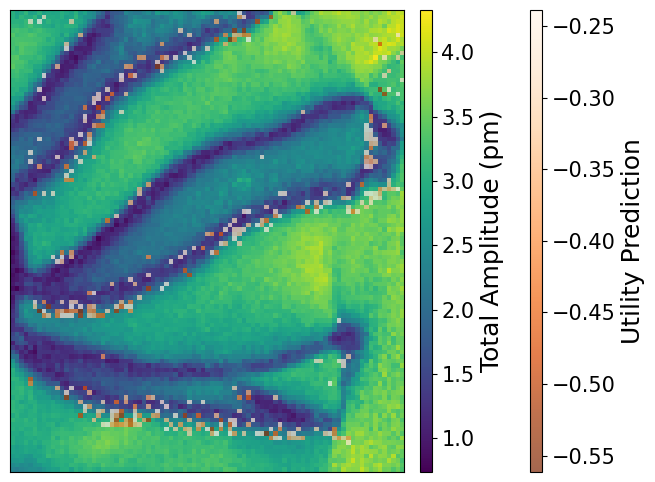

In [37]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# -----------------------------
# Build utility map
# -----------------------------
values = mean.flatten() + (var.flatten())

rows = coords[:, 0]
cols = coords[:, 1]

nrows = rows.max() + 1
ncols = cols.max() + 1

grid = np.full((nrows, ncols), np.nan)
grid[rows, cols] = values

threshold = np.nanpercentile(grid, 5)
masked_grid = np.ma.masked_where(grid > threshold, grid)

# -----------------------------
# Figure
# -----------------------------
fig, ax = plt.subplots(figsize=(8, 6), dpi=100, frameon=False)

# Shift everything slightly left to make room for colorbars
fig.subplots_adjust(right=0.72)

# Base image
im_base = ax.imshow(
    struc_img * 1e12,
    origin='lower',
    cmap='viridis',
    interpolation='nearest'
)

# Overlay
im_overlay = ax.imshow(
    masked_grid,
    origin='lower',
    cmap='Oranges_r',
    alpha=0.7,
    interpolation='nearest'
)

# Clean axes
ax.set_xticks([])
ax.set_yticks([])

# -----------------------------
# Colorbars
# -----------------------------
cax_green = inset_axes(
    ax,
    width="3%",
    height="100%",
    loc="lower left",
    bbox_to_anchor=(1.04, 0.0, 1, 1),
    bbox_transform=ax.transAxes,
    borderpad=0
)

cax_red = inset_axes(
    ax,
    width="3%",
    height="100%",
    loc="lower left",
    bbox_to_anchor=(1.32, 0.0, 1, 1),
    bbox_transform=ax.transAxes,
    borderpad=0
)

cbar_green = fig.colorbar(im_base, cax=cax_green)
cbar_green.set_label("Total Amplitude (pm)", fontsize=18)
cbar_green.ax.tick_params(labelsize=15)

cbar_red = fig.colorbar(im_overlay, cax=cax_red)
cbar_red.set_label("Utility Prediction", fontsize=18)
cbar_red.ax.tick_params(labelsize=15)

plt.savefig('EMO DKPL_2.png', dpi=600)
plt.savefig('EMO DKPL_2.eps')
plt.show()